# Randome Freezing

In [ ]:
import torch
import torchvision
import torchvision.transforms as transforms
from torchvision.models import resnet18
import random
import copy

# ---------------- DEVICE ----------------
device = torch.device("cuda" if torch.cuda.is_available() else "cpu")
print("Using:", device)

# ---------------- DATA (augmentation reduces overfitting) ----------------
transform_train = transforms.Compose([
    transforms.Resize(224),
    transforms.RandomHorizontalFlip(),
    transforms.RandomCrop(224, padding=4),
    transforms.ToTensor()
])

transform_test = transforms.Compose([
    transforms.Resize(224),
    transforms.ToTensor()
])

trainset = torchvision.datasets.CIFAR100('./data', train=True, download=True, transform=transform_train)
trainloader = torch.utils.data.DataLoader(trainset, batch_size=64, shuffle=True, num_workers=2)

testset = torchvision.datasets.CIFAR100('./data', train=False, download=True, transform=transform_test)
testloader = torch.utils.data.DataLoader(testset, batch_size=64, shuffle=False, num_workers=2)

# ---------------- MODEL (pretrained helps a lot) ----------------
model = resnet18(weights="IMAGENET1K_V1")

# dropout added to reduce overfitting
model.fc = torch.nn.Sequential(
    torch.nn.Dropout(0.5),
    torch.nn.Linear(512,100)
)

model = model.to(device)

# ---------------- FREEZE ALL ----------------
for p in model.parameters():
    p.requires_grad = False

# accuracy function
def accuracy_loader(model, loader):
    model.eval()
    correct,total=0,0
    with torch.no_grad():
        for x,y in loader:
            x,y=x.to(device),y.to(device)
            out=model(x)
            _,pred=out.max(1)
            total+=y.size(0)
            correct+=pred.eq(y).sum().item()
    return correct/total

best_acc = accuracy_loader(model,testloader)
print("Initial test acc:",best_acc)

layers = {
    "layer1": model.layer1,
    "layer2": model.layer2,
    "layer3": model.layer3,
    "layer4": model.layer4
}

# ---------------- RANDOMIZED TRAINING ----------------
for i in range(40):

    print("\nIteration",i+1)

    # choose 1 or 2 layers randomly
    chosen_names = random.sample(list(layers.keys()), random.choice([1,2]))
    print("Unfreezing:",chosen_names)

    old_weights = copy.deepcopy(model.state_dict())

    # unfreeze chosen layers
    for name in chosen_names:
        for p in layers[name].parameters():
            p.requires_grad=True

    # FC ALWAYS train
    for p in model.fc.parameters():
        p.requires_grad=True

    optimizer = torch.optim.Adam(
        filter(lambda p:p.requires_grad,model.parameters()),
        lr=3e-4,
        weight_decay=1e-4   # key for overfitting
    )

    scheduler = torch.optim.lr_scheduler.CosineAnnealingLR(optimizer, T_max=3)

    loss_fn=torch.nn.CrossEntropyLoss()

    # training
    model.train()
    for epoch in range(3):
        for x,y in trainloader:
            x,y=x.to(device),y.to(device)

            optimizer.zero_grad()
            out=model(x)
            loss=loss_fn(out,y)
            loss.backward()
            optimizer.step()

        scheduler.step()

    train_acc = accuracy_loader(model,trainloader)
    test_acc  = accuracy_loader(model,testloader)

    print("Train:",train_acc)
    print("Test :",test_acc)

    if test_acc > best_acc:
        best_acc=test_acc
        print("✅ Improved")
    else:
        model.load_state_dict(old_weights)
        print("❌ Reverted")

    # freeze again
    for p in model.parameters():
        p.requires_grad=False

print("\nFinal best:",best_acc)

In [1]:
import torch
import torchvision
import torchvision.transforms as transforms
from torchvision.models import resnet18
import random
import copy
import os

# ---------------- DEVICE ----------------
device = torch.device("cuda" if torch.cuda.is_available() else "cpu")
print("Using:", device)

# ---------------- DATA ----------------
transform_train = transforms.Compose([
    transforms.Resize(224),
    transforms.RandomHorizontalFlip(),
    transforms.RandomCrop(224, padding=4),
    transforms.ToTensor()
])

transform_test = transforms.Compose([
    transforms.Resize(224),
    transforms.ToTensor()
])

trainset = torchvision.datasets.CIFAR100(
    root='./data',
    train=True,
    download=True,
    transform=transform_train
)

testset = torchvision.datasets.CIFAR100(
    root='./data',
    train=False,
    download=True,
    transform=transform_test
)

trainloader = torch.utils.data.DataLoader(
    trainset,
    batch_size=64,
    shuffle=True,
    num_workers=2
)

testloader = torch.utils.data.DataLoader(
    testset,
    batch_size=64,
    shuffle=False,
    num_workers=2
)

# ---------------- MODEL ----------------
model = resnet18(weights="IMAGENET1K_V1")

model.fc = torch.nn.Sequential(
    torch.nn.Dropout(0.5),
    torch.nn.Linear(512, 100)
)

model = model.to(device)

# ---------------- FREEZE ALL ----------------
for p in model.parameters():
    p.requires_grad = False

# ---------------- ACCURACY FUNCTION ----------------
def accuracy_loader(model, loader):
    model.eval()
    correct, total = 0, 0
    with torch.no_grad():
        for x, y in loader:
            x, y = x.to(device), y.to(device)
            out = model(x)
            _, pred = out.max(1)
            total += y.size(0)
            correct += pred.eq(y).sum().item()
    return correct / total

# ---------------- TRAINING SETUP ----------------
best_acc = accuracy_loader(model, testloader)
print("Initial test accuracy:", best_acc)

layers = {
    "layer1": model.layer1,
    "layer2": model.layer2,
    "layer3": model.layer3,
    "layer4": model.layer4
}

patience = 5
no_improve_count = 0
max_iterations = 40

# ---------------- RANDOMIZED TRAINING LOOP ----------------
for i in range(max_iterations):

    print("\n========== Iteration", i + 1, "==========")

    chosen_names = random.sample(
        list(layers.keys()),
        random.choice([1, 2])
    )

    print("Unfreezing:", chosen_names)

    old_weights = copy.deepcopy(model.state_dict())

    # Unfreeze selected layers
    for name in chosen_names:
        for p in layers[name].parameters():
            p.requires_grad = True

    # Always train FC
    for p in model.fc.parameters():
        p.requires_grad = True

    optimizer = torch.optim.Adam(
        filter(lambda p: p.requires_grad, model.parameters()),
        lr=3e-4,
        weight_decay=1e-4
    )

    scheduler = torch.optim.lr_scheduler.CosineAnnealingLR(
        optimizer,
        T_max=3
    )

    loss_fn = torch.nn.CrossEntropyLoss()

    # -------- TRAIN --------
    model.train()

    for epoch in range(3):
        for x, y in trainloader:
            x, y = x.to(device), y.to(device)

            optimizer.zero_grad()
            out = model(x)
            loss = loss_fn(out, y)
            loss.backward()
            optimizer.step()

        scheduler.step()

    # -------- EVALUATE --------
    train_acc = accuracy_loader(model, trainloader)
    test_acc = accuracy_loader(model, testloader)

    print("Train Accuracy:", train_acc)
    print("Test Accuracy :", test_acc)

    # -------- EARLY STOPPING --------
    if test_acc > best_acc:
        best_acc = test_acc
        no_improve_count = 0
        torch.save(model.state_dict(), "best_model.pth")
        print("✅ Improved — Model Saved")
    else:
        model.load_state_dict(old_weights)
        no_improve_count += 1
        print("❌ Reverted | No Improve Count:", no_improve_count)

    # Freeze again
    for p in model.parameters():
        p.requires_grad = False

    # Stop if no improvement for patience rounds
    if no_improve_count >= patience:
        print("\n🛑 Early stopping triggered!")
        break

print("\nFinal Best Accuracy:", best_acc)
print("Best model saved as best_model.pth")

Using: cuda


100%|██████████| 169M/169M [00:02<00:00, 61.4MB/s] 


Downloading: "https://download.pytorch.org/models/resnet18-f37072fd.pth" to /root/.cache/torch/hub/checkpoints/resnet18-f37072fd.pth


100%|██████████| 44.7M/44.7M [00:00<00:00, 185MB/s] 


Initial test accuracy: 0.0091

========== Iteration 1 ==========
Unfreezing: ['layer3']
Train Accuracy: 0.75712
Test Accuracy : 0.7054
✅ Improved — Model Saved

========== Iteration 2 ==========
Unfreezing: ['layer2', 'layer3']
Train Accuracy: 0.84694
Test Accuracy : 0.758
✅ Improved — Model Saved

========== Iteration 3 ==========
Unfreezing: ['layer1', 'layer3']
Train Accuracy: 0.89264
Test Accuracy : 0.7757
✅ Improved — Model Saved

========== Iteration 4 ==========
Unfreezing: ['layer4', 'layer1']
Train Accuracy: 0.94616
Test Accuracy : 0.7912
✅ Improved — Model Saved

========== Iteration 5 ==========
Unfreezing: ['layer3']
Train Accuracy: 0.97058
Test Accuracy : 0.7984
✅ Improved — Model Saved

========== Iteration 6 ==========
Unfreezing: ['layer3']
Train Accuracy: 0.97966
Test Accuracy : 0.7984
❌ Reverted | No Improve Count: 1

========== Iteration 7 ==========
Unfreezing: ['layer3', 'layer4']
Train Accuracy: 0.9772
Test Accuracy : 0.795
❌ Reverted | No Improve Count: 2

======

Model Loaded

✅ Accuracy: 0.8011

📊 Classification Report:
               precision    recall  f1-score   support

        apple       0.92      0.93      0.93       100
aquarium_fish       0.93      0.87      0.90       100
         baby       0.71      0.66      0.68       100
         bear       0.64      0.67      0.66       100
       beaver       0.67      0.68      0.68       100
          bed       0.83      0.80      0.82       100
          bee       0.82      0.87      0.84       100
       beetle       0.73      0.77      0.75       100
      bicycle       0.95      0.91      0.93       100
       bottle       0.95      0.87      0.91       100
         bowl       0.64      0.64      0.64       100
          boy       0.60      0.57      0.58       100
       bridge       0.85      0.90      0.87       100
          bus       0.81      0.78      0.80       100
    butterfly       0.86      0.76      0.81       100
        camel       0.75      0.85      0.79       100
     

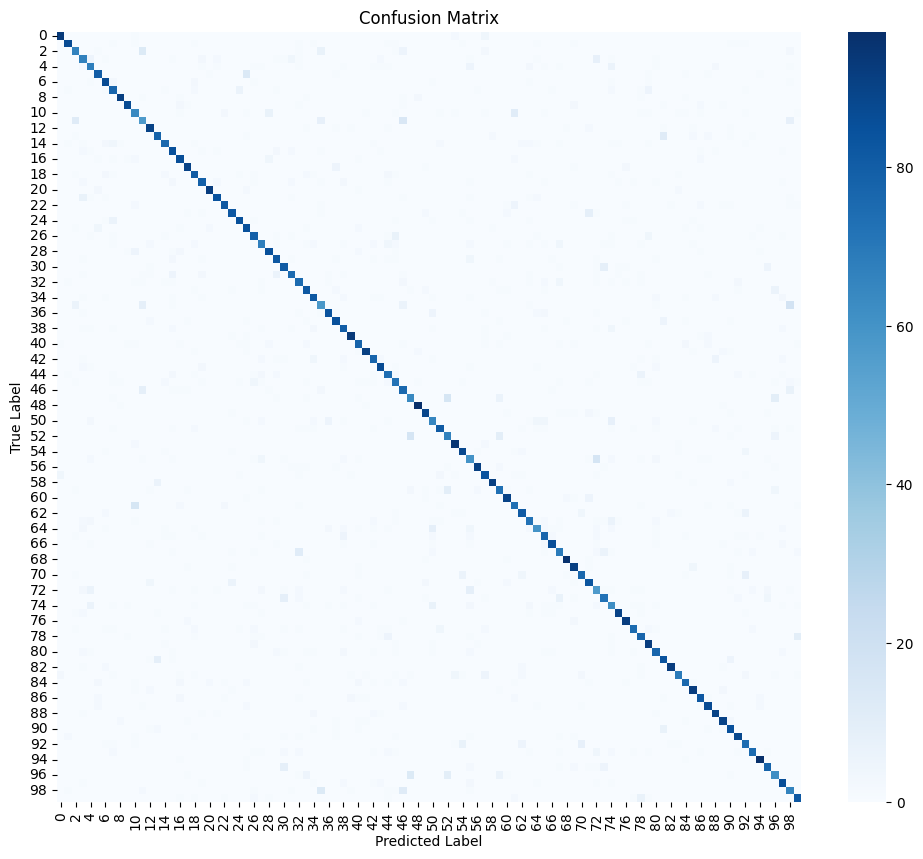

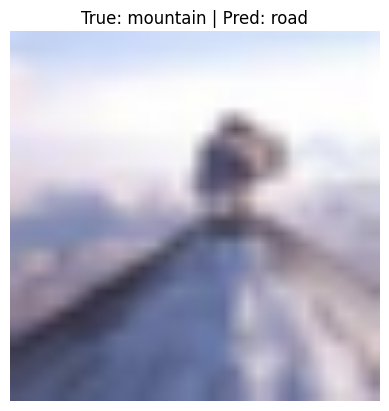

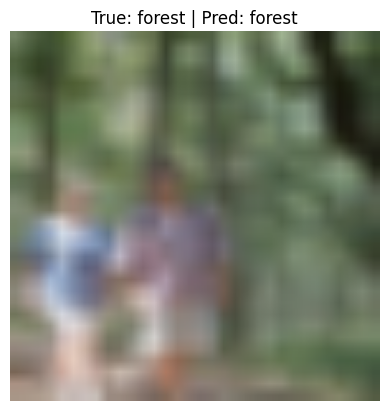

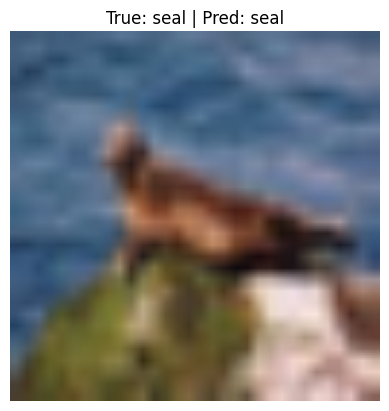

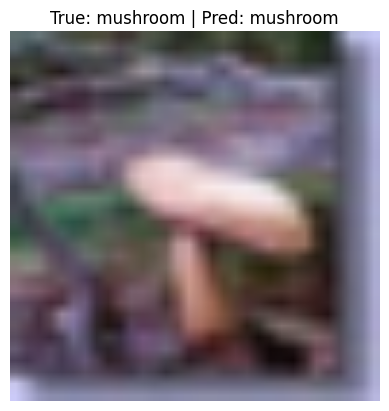

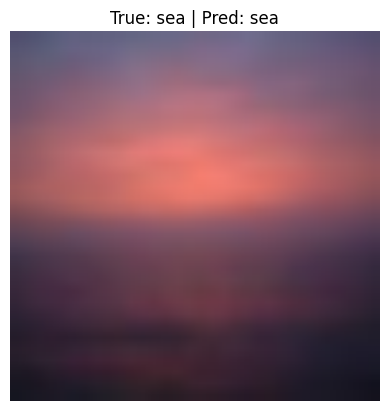

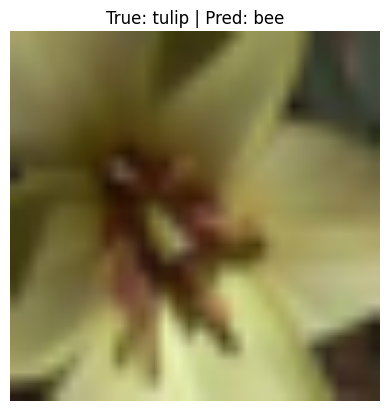

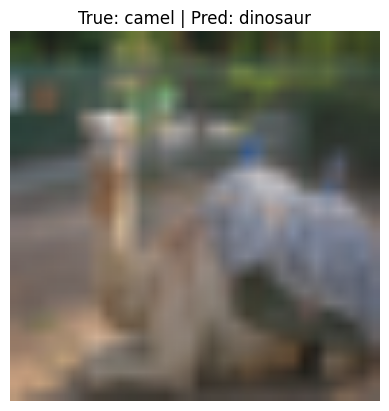

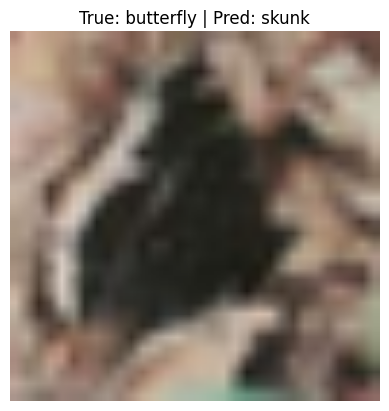

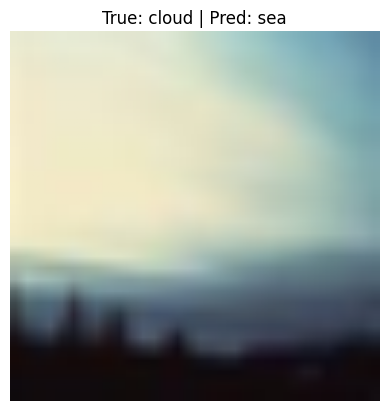

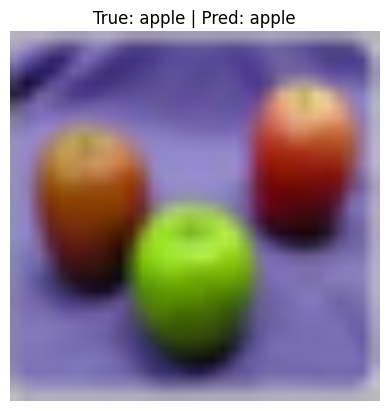

In [2]:
import torch
import torchvision
import torchvision.transforms as transforms
from torchvision.models import resnet18
import matplotlib.pyplot as plt
import numpy as np
from sklearn.metrics import confusion_matrix, classification_report, accuracy_score
import seaborn as sns

# ---------------- DEVICE ----------------
device = torch.device("cuda" if torch.cuda.is_available() else "cpu")

# ---------------- DATA ----------------
transform = transforms.Compose([
    transforms.Resize(224),
    transforms.ToTensor()
])

testset = torchvision.datasets.CIFAR100(
    root='./data',
    train=False,
    download=True,
    transform=transform
)

testloader = torch.utils.data.DataLoader(
    testset,
    batch_size=64,
    shuffle=False
)

classes = testset.classes

# ---------------- LOAD MODEL ----------------
model = resnet18(weights=None)

model.fc = torch.nn.Sequential(
    torch.nn.Dropout(0.5),
    torch.nn.Linear(512, 100)
)

model.load_state_dict(torch.load("best_model.pth"))
model.to(device)
model.eval()

print("Model Loaded")

# ---------------- PREDICTIONS ----------------
all_preds = []
all_labels = []

with torch.no_grad():
    for images, labels in testloader:

        images = images.to(device)
        labels = labels.to(device)

        outputs = model(images)
        _, preds = torch.max(outputs, 1)

        all_preds.extend(preds.cpu().numpy())
        all_labels.extend(labels.cpu().numpy())

# ---------------- METRICS ----------------
acc = accuracy_score(all_labels, all_preds)

print("\n✅ Accuracy:", acc)

print("\n📊 Classification Report:")
print(classification_report(all_labels, all_preds, target_names=classes))

# ---------------- CONFUSION MATRIX ----------------
cm = confusion_matrix(all_labels, all_preds)

plt.figure(figsize=(12,10))
sns.heatmap(cm, cmap="Blues")
plt.title("Confusion Matrix")
plt.xlabel("Predicted Label")
plt.ylabel("True Label")
plt.show()

# ---------------- SHOW SAMPLE PREDICTIONS ----------------

def show_predictions(loader, model, classes, num_images=6):

    model.eval()

    images_shown = 0

    with torch.no_grad():
        for images, labels in loader:

            images = images.to(device)
            labels = labels.to(device)

            outputs = model(images)
            _, preds = torch.max(outputs, 1)

            for i in range(images.size(0)):

                img = images[i].cpu().permute(1,2,0).numpy()

                true_label = classes[labels[i]]
                pred_label = classes[preds[i]]

                plt.imshow(img)
                plt.title(f"True: {true_label} | Pred: {pred_label}")
                plt.axis("off")
                plt.show()

                images_shown += 1

                if images_shown >= num_images:
                    return

show_predictions(testloader, model, classes, 10)

# Added Norimalization and DataAUG

In [4]:
import torch
import torchvision
import torchvision.transforms as transforms
from torchvision.models import resnet18
import random
import copy

# ---------------- DEVICE ----------------
device = torch.device("cuda" if torch.cuda.is_available() else "cpu")
print("Using:", device)

# ---------------- DATA TRANSFORMS ----------------
transform_train = transforms.Compose([
    transforms.Resize(224),
    transforms.RandomHorizontalFlip(),
    transforms.RandomCrop(224, padding=4),
    transforms.RandomRotation(15),
    transforms.ColorJitter(brightness=0.2, contrast=0.2, saturation=0.2),
    transforms.ToTensor(),
    transforms.Normalize(
        mean=[0.485, 0.456, 0.406],
        std=[0.229, 0.224, 0.225]
    ),
    transforms.RandomErasing(p=0.25)
])

transform_test = transforms.Compose([
    transforms.Resize(224),
    transforms.ToTensor(),
    transforms.Normalize(
        mean=[0.485, 0.456, 0.406],
        std=[0.229, 0.224, 0.225]
    )
])

# ---------------- DATASETS ----------------
trainset = torchvision.datasets.CIFAR100(
    root='./data',
    train=True,
    download=True,
    transform=transform_train
)

testset = torchvision.datasets.CIFAR100(
    root='./data',
    train=False,
    download=True,
    transform=transform_test
)

trainloader = torch.utils.data.DataLoader(
    trainset,
    batch_size=64,
    shuffle=True,
    num_workers=2
)

testloader = torch.utils.data.DataLoader(
    testset,
    batch_size=64,
    shuffle=False,
    num_workers=2
)

# ---------------- MODEL ----------------
model = resnet18(weights="IMAGENET1K_V1")

model.fc = torch.nn.Sequential(
    torch.nn.Dropout(0.5),
    torch.nn.Linear(512, 100)
)

model = model.to(device)

# ---------------- FREEZE ALL ----------------
for p in model.parameters():
    p.requires_grad = False

# ---------------- ACCURACY FUNCTION ----------------
def accuracy_loader(model, loader):
    model.eval()
    correct, total = 0, 0

    with torch.no_grad():
        for x, y in loader:
            x, y = x.to(device), y.to(device)

            out = model(x)
            _, pred = out.max(1)

            total += y.size(0)
            correct += pred.eq(y).sum().item()

    return correct / total


# ---------------- INITIAL ACCURACY ----------------
best_acc = accuracy_loader(model, testloader)
print("Initial Test Accuracy:", best_acc)

# ---------------- LAYERS ----------------
layers = {
    "layer1": model.layer1,
    "layer2": model.layer2,
    "layer3": model.layer3,
    "layer4": model.layer4
}

patience = 3
no_improve_count = 0
max_iterations = 40

# ---------------- TRAINING LOOP ----------------
for i in range(max_iterations):

    print("\n========== Iteration", i + 1, "==========")

    chosen_names = random.sample(
        list(layers.keys()),
        random.choice([1, 2])
    )

    print("Unfreezing:", chosen_names)

    old_weights = copy.deepcopy(model.state_dict())

    # -------- UNFREEZE RANDOM LAYERS --------
    for name in chosen_names:
        for p in layers[name].parameters():
            p.requires_grad = True

    # -------- ALWAYS TRAIN FC --------
    for p in model.fc.parameters():
        p.requires_grad = True

    optimizer = torch.optim.AdamW(
        filter(lambda p: p.requires_grad, model.parameters()),
        lr=3e-4,
        weight_decay=1e-4
    )

    scheduler = torch.optim.lr_scheduler.CosineAnnealingLR(
        optimizer,
        T_max=8
    )

    # -------- LABEL SMOOTHING LOSS --------
    loss_fn = torch.nn.CrossEntropyLoss(label_smoothing=0.1)

    # -------- TRAIN --------
    model.train()

    for epoch in range(8):

        running_loss = 0

        for x, y in trainloader:

            x, y = x.to(device), y.to(device)

            optimizer.zero_grad()

            out = model(x)

            loss = loss_fn(out, y)

            loss.backward()

            optimizer.step()

            running_loss += loss.item()

        scheduler.step()

        print(f"Epoch {epoch+1} Loss: {running_loss/len(trainloader):.4f}")

    # -------- EVALUATE --------
    train_acc = accuracy_loader(model, trainloader)
    test_acc = accuracy_loader(model, testloader)

    print("Train Accuracy:", train_acc)
    print("Test Accuracy :", test_acc)

    # -------- SAVE BEST MODEL --------
    if test_acc > best_acc:

        best_acc = test_acc
        no_improve_count = 0

        torch.save(model.state_dict(), "best_model.pth")

        print("✅ Improved — Model Saved")

    else:

        model.load_state_dict(old_weights)

        no_improve_count += 1

        print("❌ Reverted | No Improve Count:", no_improve_count)

    # -------- FREEZE AGAIN --------
    for p in model.parameters():
        p.requires_grad = False

    # -------- EARLY STOPPING --------
    if no_improve_count >= patience:

        print("\n🛑 Early stopping triggered!")

        break


print("\nFinal Best Accuracy:", best_acc)
print("Best model saved as best_model.pth")

Using: cuda
Downloading: "https://download.pytorch.org/models/resnet18-f37072fd.pth" to /root/.cache/torch/hub/checkpoints/resnet18-f37072fd.pth


100%|██████████| 44.7M/44.7M [00:00<00:00, 165MB/s] 


Initial Test Accuracy: 0.0072

========== Iteration 1 ==========
Unfreezing: ['layer2', 'layer1']
Epoch 1 Loss: 3.8361
Epoch 2 Loss: 2.6963
Epoch 3 Loss: 2.3672
Epoch 4 Loss: 2.2214
Epoch 5 Loss: 2.1430
Epoch 6 Loss: 2.0776
Epoch 7 Loss: 2.0383
Epoch 8 Loss: 2.0178
Train Accuracy: 0.73316
Test Accuracy : 0.741
✅ Improved — Model Saved

========== Iteration 2 ==========
Unfreezing: ['layer4']
Epoch 1 Loss: 1.9784
Epoch 2 Loss: 1.7502
Epoch 3 Loss: 1.6168
Epoch 4 Loss: 1.5047
Epoch 5 Loss: 1.4118
Epoch 6 Loss: 1.3235
Epoch 7 Loss: 1.2676
Epoch 8 Loss: 1.2356
Train Accuracy: 0.92938
Test Accuracy : 0.8259
✅ Improved — Model Saved

========== Iteration 3 ==========
Unfreezing: ['layer3', 'layer2']
Epoch 1 Loss: 1.3920
Epoch 2 Loss: 1.3494
Epoch 3 Loss: 1.3095
Epoch 4 Loss: 1.2724
Epoch 5 Loss: 1.2311
Epoch 6 Loss: 1.2024
Epoch 7 Loss: 1.1734
Epoch 3 Loss: 1.2398
Epoch 4 Loss: 1.2113
Epoch 5 Loss: 1.1854
Epoch 6 Loss: 1.1550
Epoch 7 Loss: 1.1366
Epoch 8 Loss: 1.1228
Train Accuracy: 0.96082


Model Loaded

✅ Accuracy: 0.835

📊 Classification Report:
               precision    recall  f1-score   support

        apple       0.93      0.92      0.92       100
aquarium_fish       0.94      0.95      0.95       100
         baby       0.71      0.75      0.73       100
         bear       0.73      0.78      0.75       100
       beaver       0.72      0.65      0.68       100
          bed       0.86      0.88      0.87       100
          bee       0.95      0.94      0.94       100
       beetle       0.87      0.88      0.88       100
      bicycle       0.99      0.94      0.96       100
       bottle       0.93      0.94      0.94       100
         bowl       0.71      0.62      0.66       100
          boy       0.60      0.66      0.63       100
       bridge       0.90      0.89      0.89       100
          bus       0.84      0.84      0.84       100
    butterfly       0.88      0.86      0.87       100
        camel       0.90      0.83      0.86       100
      

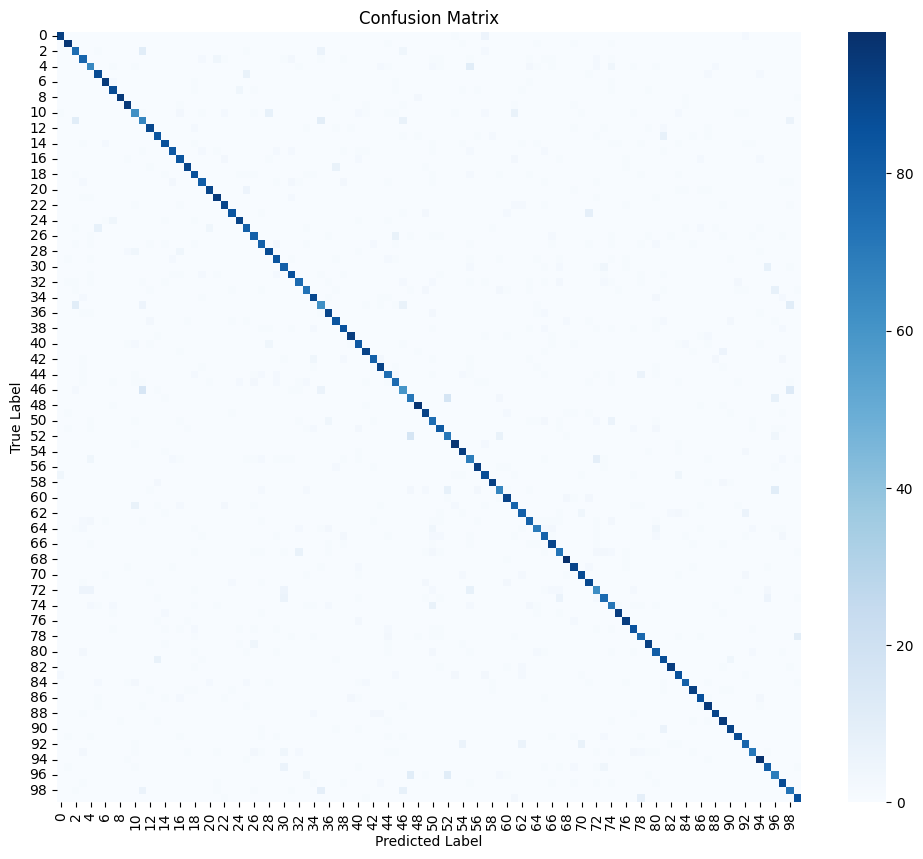

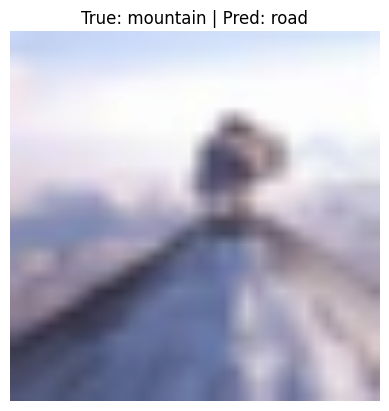

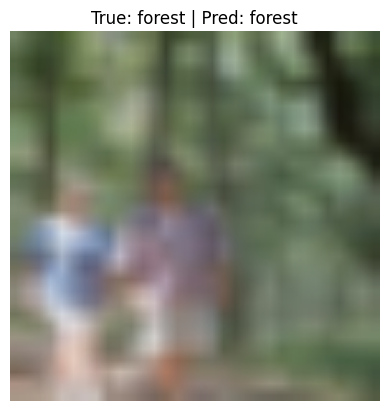

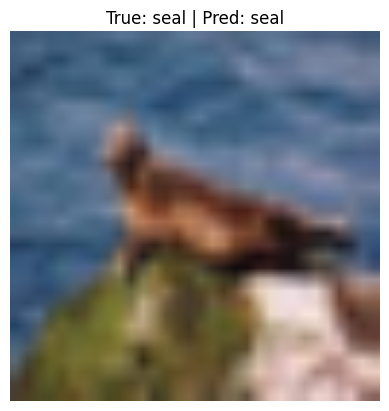

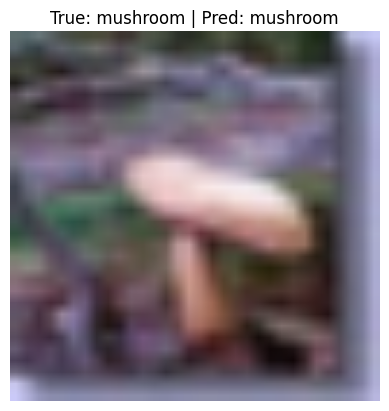

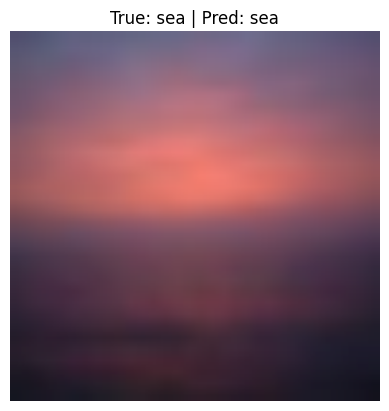

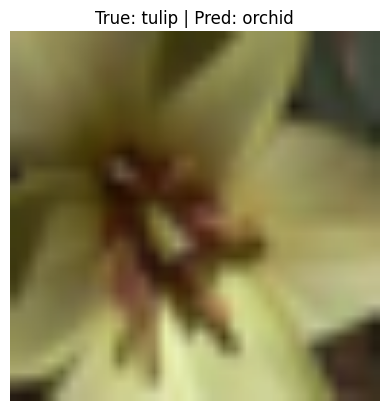

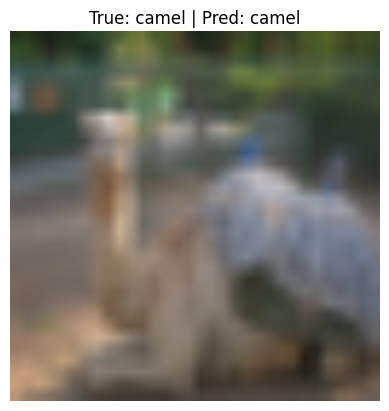

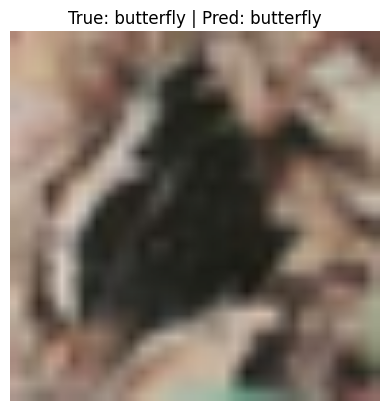

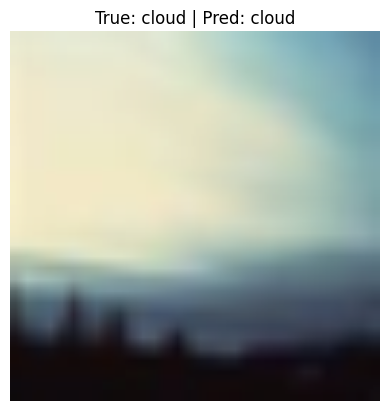

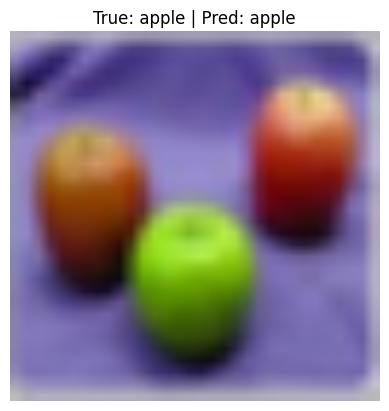

In [6]:
import torch
import torchvision
import torchvision.transforms as transforms
from torchvision.models import resnet18
import matplotlib.pyplot as plt
import numpy as np
from sklearn.metrics import confusion_matrix, classification_report, accuracy_score
import seaborn as sns

# ---------------- DEVICE ----------------
device = torch.device("cuda" if torch.cuda.is_available() else "cpu")

# ---------------- NORMALIZATION ----------------
mean = [0.485, 0.456, 0.406]
std = [0.229, 0.224, 0.225]

# ---------------- DATA ----------------
transform = transforms.Compose([
    transforms.Resize(224),
    transforms.ToTensor(),
    transforms.Normalize(mean=mean, std=std)
])

testset = torchvision.datasets.CIFAR100(
    root='./data',
    train=False,
    download=True,
    transform=transform
)

testloader = torch.utils.data.DataLoader(
    testset,
    batch_size=64,
    shuffle=False
)

classes = testset.classes

# ---------------- LOAD MODEL ----------------
model = resnet18(weights=None)

model.fc = torch.nn.Sequential(
    torch.nn.Dropout(0.5),
    torch.nn.Linear(512, 100)
)

model.load_state_dict(torch.load(
    "/kaggle/working/best_model.pth",
    map_location=device
))

model.to(device)
model.eval()

print("Model Loaded")

# ---------------- PREDICTIONS ----------------
all_preds = []
all_labels = []

with torch.no_grad():
    for images, labels in testloader:

        images = images.to(device)
        labels = labels.to(device)

        outputs = model(images)
        _, preds = torch.max(outputs, 1)

        all_preds.extend(preds.cpu().numpy())
        all_labels.extend(labels.cpu().numpy())

# ---------------- METRICS ----------------
acc = accuracy_score(all_labels, all_preds)

print("\n✅ Accuracy:", acc)

print("\n📊 Classification Report:")
print(classification_report(all_labels, all_preds, target_names=classes))

# ---------------- CONFUSION MATRIX ----------------
cm = confusion_matrix(all_labels, all_preds)

plt.figure(figsize=(12,10))
sns.heatmap(cm, cmap="Blues")
plt.title("Confusion Matrix")
plt.xlabel("Predicted Label")
plt.ylabel("True Label")
plt.show()

# ---------------- UNNORMALIZE FUNCTION ----------------
def unnormalize(img):
    img = img.numpy().transpose((1, 2, 0))
    img = std * img + mean
    img = np.clip(img, 0, 1)
    return img

# ---------------- SHOW SAMPLE PREDICTIONS ----------------
def show_predictions(loader, model, classes, num_images=6):

    model.eval()
    images_shown = 0

    with torch.no_grad():
        for images, labels in loader:

            images = images.to(device)
            labels = labels.to(device)

            outputs = model(images)
            _, preds = torch.max(outputs, 1)

            for i in range(images.size(0)):

                img = images[i].cpu()
                img = unnormalize(img)

                true_label = classes[labels[i]]
                pred_label = classes[preds[i]]

                plt.imshow(img)
                plt.title(f"True: {true_label} | Pred: {pred_label}")
                plt.axis("off")
                plt.show()

                images_shown += 1

                if images_shown >= num_images:
                    return

show_predictions(testloader, model, classes, 10)

# epochs 12

In [ ]:
import torch
import torchvision
import torchvision.transforms as transforms
from torchvision.models import resnet18
import random
import copy

# ---------------- DEVICE ----------------
device = torch.device("cuda" if torch.cuda.is_available() else "cpu")
print("Using:", device)

# ---------------- DATA TRANSFORMS ----------------
transform_train = transforms.Compose([
    transforms.Resize(224),
    transforms.RandomHorizontalFlip(),
    transforms.RandomCrop(224, padding=4),
    transforms.RandomRotation(15),
    transforms.ColorJitter(brightness=0.2, contrast=0.2, saturation=0.2),
    transforms.ToTensor(),
    transforms.Normalize(
        mean=[0.485, 0.456, 0.406],
        std=[0.229, 0.224, 0.225]
    ),
    transforms.RandomErasing(p=0.25)
])

transform_test = transforms.Compose([
    transforms.Resize(224),
    transforms.ToTensor(),
    transforms.Normalize(
        mean=[0.485, 0.456, 0.406],
        std=[0.229, 0.224, 0.225]
    )
])

# ---------------- DATASETS ----------------
trainset = torchvision.datasets.CIFAR100(
    root='./data',
    train=True,
    download=True,
    transform=transform_train
)

testset = torchvision.datasets.CIFAR100(
    root='./data',
    train=False,
    download=True,
    transform=transform_test
)

trainloader = torch.utils.data.DataLoader(
    trainset,
    batch_size=64,
    shuffle=True,
    num_workers=2
)

testloader = torch.utils.data.DataLoader(
    testset,
    batch_size=64,
    shuffle=False,
    num_workers=2
)

# ---------------- MODEL ----------------
model = resnet18(weights="IMAGENET1K_V1")

model.fc = torch.nn.Sequential(
    torch.nn.Dropout(0.5),
    torch.nn.Linear(512, 100)
)

model = model.to(device)

# ---------------- FREEZE ALL ----------------
for p in model.parameters():
    p.requires_grad = False

# ---------------- ACCURACY FUNCTION ----------------
def accuracy_loader(model, loader):
    model.eval()
    correct, total = 0, 0

    with torch.no_grad():
        for x, y in loader:
            x, y = x.to(device), y.to(device)

            out = model(x)
            _, pred = out.max(1)

            total += y.size(0)
            correct += pred.eq(y).sum().item()

    return correct / total


# ---------------- INITIAL ACCURACY ----------------
best_acc = accuracy_loader(model, testloader)
print("Initial Test Accuracy:", best_acc)

# ---------------- LAYERS ----------------
layers = {
    "layer1": model.layer1,
    "layer2": model.layer2,
    "layer3": model.layer3,
    "layer4": model.layer4
}

patience = 3
no_improve_count = 0
max_iterations = 40

# ---------------- TRAINING LOOP ----------------
for i in range(max_iterations):

    print("\n========== Iteration", i + 1, "==========")

    chosen_names = random.sample(
        list(layers.keys()),
        random.choice([1, 2])
    )

    print("Unfreezing:", chosen_names)

    old_weights = copy.deepcopy(model.state_dict())

    # -------- UNFREEZE RANDOM LAYERS --------
    for name in chosen_names:
        for p in layers[name].parameters():
            p.requires_grad = True

    # -------- ALWAYS TRAIN FC --------
    for p in model.fc.parameters():
        p.requires_grad = True

    optimizer = torch.optim.AdamW(
        filter(lambda p: p.requires_grad, model.parameters()),
        lr=3e-4,
        weight_decay=1e-4
    )

    scheduler = torch.optim.lr_scheduler.CosineAnnealingLR(
        optimizer,
        T_max=12   # 🔥 updated
    )

    # -------- LABEL SMOOTHING LOSS --------
    loss_fn = torch.nn.CrossEntropyLoss(label_smoothing=0.1)

    # -------- TRAIN --------
    model.train()

    for epoch in range(12):   # 🔥 changed to 12

        running_loss = 0

        for x, y in trainloader:

            x, y = x.to(device), y.to(device)

            optimizer.zero_grad()

            out = model(x)

            loss = loss_fn(out, y)

            loss.backward()

            optimizer.step()

            running_loss += loss.item()

        scheduler.step()

        print(f"Epoch {epoch+1} Loss: {running_loss/len(trainloader):.4f}")

    # -------- EVALUATE --------
    train_acc = accuracy_loader(model, trainloader)
    test_acc = accuracy_loader(model, testloader)

    print("Train Accuracy:", train_acc)
    print("Test Accuracy :", test_acc)

    # -------- SAVE BEST MODEL --------
    if test_acc > best_acc:

        best_acc = test_acc
        no_improve_count = 0

        torch.save(model.state_dict(), "best_model.pth")

        print("✅ Improved — Model Saved")

    else:

        model.load_state_dict(old_weights)

        no_improve_count += 1

        print("❌ Reverted | No Improve Count:", no_improve_count)

    # -------- FREEZE AGAIN --------
    for p in model.parameters():
        p.requires_grad = False

    # -------- EARLY STOPPING --------
    if no_improve_count >= patience:

        print("\n🛑 Early stopping triggered!")
        break


print("\nFinal Best Accuracy:", best_acc)
print("Best model saved as best_model.pth")

Using: cuda


100%|██████████| 169M/169M [00:04<00:00, 34.8MB/s] 


Downloading: "https://download.pytorch.org/models/resnet18-f37072fd.pth" to /root/.cache/torch/hub/checkpoints/resnet18-f37072fd.pth


100%|██████████| 44.7M/44.7M [00:00<00:00, 191MB/s]


Initial Test Accuracy: 0.0113

========== Iteration 1 ==========
Unfreezing: ['layer4']
Epoch 1 Loss: 2.6686
Epoch 2 Loss: 2.1022
Epoch 3 Loss: 1.9332
Epoch 4 Loss: 1.8176
Epoch 5 Loss: 1.7168
Epoch 6 Loss: 1.6334
Epoch 7 Loss: 1.5584
Epoch 8 Loss: 1.4844
Epoch 9 Loss: 1.4297
Epoch 10 Loss: 1.3891
Epoch 11 Loss: 1.3590
Epoch 12 Loss: 1.3434
Train Accuracy: 0.89258
Test Accuracy : 0.7877
✅ Improved — Model Saved

========== Iteration 2 ==========
Unfreezing: ['layer4']
Epoch 1 Loss: 1.5473
Epoch 2 Loss: 1.5253
Epoch 3 Loss: 1.4784
Epoch 4 Loss: 1.4243
Epoch 5 Loss: 1.3751
Epoch 6 Loss: 1.3333
Epoch 7 Loss: 1.2801
Epoch 8 Loss: 1.2367
Epoch 9 Loss: 1.2088
Epoch 10 Loss: 1.1822
Epoch 11 Loss: 1.1631
Epoch 12 Loss: 1.1559
Train Accuracy: 0.942
Test Accuracy : 0.7861
❌ Reverted | No Improve Count: 1

========== Iteration 3 ==========
Unfreezing: ['layer3']
Epoch 1 Loss: 1.4353
Epoch 2 Loss: 1.3962
Epoch 3 Loss: 1.3691
Epoch 4 Loss: 1.3429
Epoch 5 Loss: 1.3236
Epoch 6 Loss: 1.2948
Epoch 7 Lo

In [ ]:
import torch
import torchvision
import torchvision.transforms as transforms
from torchvision.models import resnet18
import random
import copy

# ---------------- DEVICE ----------------
device = torch.device("cuda" if torch.cuda.is_available() else "cpu")
print("Using:", device)

# ---------------- DATA TRANSFORMS ----------------
transform_train = transforms.Compose([
    transforms.Resize(224),
    transforms.RandomHorizontalFlip(),
    transforms.RandomCrop(224, padding=4),
    transforms.RandomRotation(15),
    transforms.ColorJitter(brightness=0.2, contrast=0.2, saturation=0.2),
    transforms.ToTensor(),
    transforms.Normalize(
        mean=[0.485, 0.456, 0.406],
        std=[0.229, 0.224, 0.225]
    ),
    transforms.RandomErasing(p=0.25)
])

transform_test = transforms.Compose([
    transforms.Resize(224),
    transforms.ToTensor(),
    transforms.Normalize(
        mean=[0.485, 0.456, 0.406],
        std=[0.229, 0.224, 0.225]
    )
])

# ---------------- DATASETS ----------------
trainset = torchvision.datasets.CIFAR100(
    root='./data',
    train=True,
    download=True,
    transform=transform_train
)

testset = torchvision.datasets.CIFAR100(
    root='./data',
    train=False,
    download=True,
    transform=transform_test
)

trainloader = torch.utils.data.DataLoader(
    trainset,
    batch_size=64,
    shuffle=True,
    num_workers=2
)

testloader = torch.utils.data.DataLoader(
    testset,
    batch_size=64,
    shuffle=False,
    num_workers=2
)

# ---------------- MODEL ----------------
model = resnet18(weights="IMAGENET1K_V1")

model.fc = torch.nn.Sequential(
    torch.nn.Dropout(0.5),
    torch.nn.Linear(512, 100)
)

model = model.to(device)

# ---------------- FREEZE ALL ----------------
for p in model.parameters():
    p.requires_grad = False

# ---------------- ACCURACY FUNCTION ----------------
def accuracy_loader(model, loader):
    model.eval()
    correct, total = 0, 0

    with torch.no_grad():
        for x, y in loader:
            x, y = x.to(device), y.to(device)

            out = model(x)
            _, pred = out.max(1)

            total += y.size(0)
            correct += pred.eq(y).sum().item()

    return correct / total


# ---------------- INITIAL ACCURACY ----------------
best_acc = accuracy_loader(model, testloader)
print("Initial Test Accuracy:", best_acc)

# ---------------- LAYERS ----------------
layers = {
    "layer1": model.layer1,
    "layer2": model.layer2,
    "layer3": model.layer3,
    "layer4": model.layer4
}

patience = 3
no_improve_count = 0
max_iterations = 40

# ---------------- TRAINING LOOP ----------------
for i in range(max_iterations):

    print("\n========== Iteration", i + 1, "==========")

    chosen_names = random.sample(
        list(layers.keys()),
        random.choice([1, 2])
    )

    print("Unfreezing:", chosen_names)

    old_weights = copy.deepcopy(model.state_dict())

    # -------- UNFREEZE RANDOM LAYERS --------
    for name in chosen_names:
        for p in layers[name].parameters():
            p.requires_grad = True

    # -------- ALWAYS TRAIN FC --------
    for p in model.fc.parameters():
        p.requires_grad = True

    optimizer = torch.optim.AdamW(
        filter(lambda p: p.requires_grad, model.parameters()),
        lr=3e-4,
        weight_decay=1e-4
    )

    # -------- LABEL SMOOTHING LOSS --------
    loss_fn = torch.nn.CrossEntropyLoss(label_smoothing=0.1)

    # -------- TRAIN --------
    model.train()

    for epoch in range(8):

        running_loss = 0

        for x, y in trainloader:

            x, y = x.to(device), y.to(device)

            optimizer.zero_grad()

            out = model(x)

            loss = loss_fn(out, y)

            loss.backward()

            optimizer.step()

            running_loss += loss.item()

        print(f"Epoch {epoch+1} Loss: {running_loss/len(trainloader):.4f}")

    # -------- EVALUATE --------
    train_acc = accuracy_loader(model, trainloader)
    test_acc = accuracy_loader(model, testloader)

    print("Train Accuracy:", train_acc)
    print("Test Accuracy :", test_acc)

    # -------- SAVE BEST MODEL --------
    if test_acc > best_acc:

        best_acc = test_acc
        no_improve_count = 0

        torch.save(model.state_dict(), "best_model.pth")

        print("✅ Improved — Model Saved")

    else:

        model.load_state_dict(old_weights)

        no_improve_count += 1

        print("❌ Reverted | No Improve Count:", no_improve_count)

    # -------- FREEZE AGAIN --------
    for p in model.parameters():
        p.requires_grad = False

    # -------- EARLY STOPPING --------
    if no_improve_count >= patience:

        print("\n🛑 Early stopping triggered!")

        break


print("\nFinal Best Accuracy:", best_acc)
print("Best model saved as best_model.pth")

Using: cuda


100%|██████████| 169M/169M [00:03<00:00, 53.9MB/s] 


Downloading: "https://download.pytorch.org/models/resnet18-f37072fd.pth" to /root/.cache/torch/hub/checkpoints/resnet18-f37072fd.pth


100%|██████████| 44.7M/44.7M [00:00<00:00, 178MB/s] 


Initial Test Accuracy: 0.0142

========== Iteration 1 ==========
Unfreezing: ['layer3']
Epoch 1 Loss: 3.5778
Epoch 2 Loss: 2.5716
Epoch 3 Loss: 2.2831
Epoch 4 Loss: 2.1449
Epoch 5 Loss: 2.0503
Epoch 6 Loss: 1.9767
Epoch 7 Loss: 1.9314
Epoch 8 Loss: 1.8860
Train Accuracy: 0.75422
Test Accuracy : 0.7297
✅ Improved — Model Saved

========== Iteration 2 ==========
Unfreezing: ['layer4', 'layer2']
Epoch 1 Loss: 1.9505
Epoch 2 Loss: 1.7693
Epoch 3 Loss: 1.6695
Epoch 4 Loss: 1.5908
Epoch 5 Loss: 1.5365
Epoch 6 Loss: 1.4835
Epoch 7 Loss: 1.4429
Epoch 8 Loss: 1.3867
Train Accuracy: 0.88174
Test Accuracy : 0.7689
✅ Improved — Model Saved

========== Iteration 3 ==========
Unfreezing: ['layer2']
Epoch 1 Loss: 1.2991
Epoch 2 Loss: 1.2868
Epoch 3 Loss: 1.2791
Epoch 4 Loss: 1.2676
Epoch 5 Loss: 1.2648
Epoch 6 Loss: 1.2666
Epoch 7 Loss: 1.2633
Epoch 8 Loss: 1.2621
Train Accuracy: 0.91358
Test Accuracy : 0.7861
✅ Improved — Model Saved

========== Iteration 4 ==========
Unfreezing: ['layer3', 'layer2'

# MNIST

In [ ]:
import torch
import torchvision
import torchvision.transforms as transforms
from torchvision.models import resnet18
import random
import copy

# ---------------- DEVICE ----------------
device = torch.device("cuda" if torch.cuda.is_available() else "cpu")
print("Using:", device)

# ---------------- DATA TRANSFORMS ----------------
transform_train = transforms.Compose([
    transforms.Resize(224),

    # MNIST FIX: convert 1-channel -> 3-channel
    transforms.Grayscale(num_output_channels=3),

    transforms.RandomRotation(10),
    transforms.ToTensor(),

    transforms.Normalize(
        mean=[0.485, 0.456, 0.406],
        std=[0.229, 0.224, 0.225]
    )
])

transform_test = transforms.Compose([
    transforms.Resize(224),
    transforms.Grayscale(num_output_channels=3),
    transforms.ToTensor(),
    transforms.Normalize(
        mean=[0.485, 0.456, 0.406],
        std=[0.229, 0.224, 0.225]
    )
])

# ---------------- DATASETS ----------------
trainset = torchvision.datasets.MNIST(
    root='./data',
    train=True,
    download=True,
    transform=transform_train
)

testset = torchvision.datasets.MNIST(
    root='./data',
    train=False,
    download=True,
    transform=transform_test
)

trainloader = torch.utils.data.DataLoader(
    trainset,
    batch_size=64,
    shuffle=True,
    num_workers=2
)

testloader = torch.utils.data.DataLoader(
    testset,
    batch_size=64,
    shuffle=False,
    num_workers=2
)

# ---------------- MODEL ----------------
model = resnet18(weights="IMAGENET1K_V1")

# FIX: output classes = 10 (MNIST)
model.fc = torch.nn.Sequential(
    torch.nn.Dropout(0.5),
    torch.nn.Linear(512, 10)
)

model = model.to(device)

# ---------------- FREEZE ALL ----------------
for p in model.parameters():
    p.requires_grad = False

# ---------------- ACCURACY FUNCTION ----------------
def accuracy_loader(model, loader):
    model.eval()
    correct, total = 0, 0

    with torch.no_grad():
        for x, y in loader:
            x, y = x.to(device), y.to(device)

            out = model(x)
            _, pred = out.max(1)

            total += y.size(0)
            correct += pred.eq(y).sum().item()

    return correct / total


# ---------------- INITIAL ACCURACY ----------------
best_acc = accuracy_loader(model, testloader)
print("Initial Test Accuracy:", best_acc)

# ---------------- LAYERS ----------------
layers = {
    "layer1": model.layer1,
    "layer2": model.layer2,
    "layer3": model.layer3,
    "layer4": model.layer4
}

patience = 3
no_improve_count = 0
max_iterations = 40

# ---------------- TRAINING LOOP ----------------
for i in range(max_iterations):

    print("\n========== Iteration", i + 1, "==========")

    chosen_names = random.sample(
        list(layers.keys()),
        random.choice([1, 2])
    )

    print("Unfreezing:", chosen_names)

    old_weights = copy.deepcopy(model.state_dict())

    # -------- UNFREEZE RANDOM LAYERS --------
    for name in chosen_names:
        for p in layers[name].parameters():
            p.requires_grad = True

    # -------- ALWAYS TRAIN FC --------
    for p in model.fc.parameters():
        p.requires_grad = True

    optimizer = torch.optim.AdamW(
        filter(lambda p: p.requires_grad, model.parameters()),
        lr=3e-4,
        weight_decay=1e-4
    )

    scheduler = torch.optim.lr_scheduler.CosineAnnealingLR(
        optimizer,
        T_max=8
    )

    loss_fn = torch.nn.CrossEntropyLoss(label_smoothing=0.1)

    # -------- TRAIN --------
    model.train()

    for epoch in range(5):  # MNIST is easy → fewer epochs needed

        running_loss = 0

        for x, y in trainloader:

            x, y = x.to(device), y.to(device)

            optimizer.zero_grad()
            out = model(x)
            loss = loss_fn(out, y)
            loss.backward()
            optimizer.step()

            running_loss += loss.item()

        scheduler.step()

        print(f"Epoch {epoch+1} Loss: {running_loss/len(trainloader):.4f}")

    # -------- EVALUATE --------
    train_acc = accuracy_loader(model, trainloader)
    test_acc = accuracy_loader(model, testloader)

    print("Train Accuracy:", train_acc)
    print("Test Accuracy :", test_acc)

    # -------- SAVE BEST MODEL --------
    if test_acc > best_acc:

        best_acc = test_acc
        no_improve_count = 0

        torch.save(model.state_dict(), "best_model_mnist.pth")

        print("✅ Improved — Model Saved")

    else:

        model.load_state_dict(old_weights)

        no_improve_count += 1

        print("❌ Reverted | No Improve Count:", no_improve_count)

    # -------- FREEZE AGAIN --------
    for p in model.parameters():
        p.requires_grad = False

    if no_improve_count >= patience:
        print("\n🛑 Early stopping triggered!")
        break

print("\nFinal Best Accuracy:", best_acc)

Using: cuda


100%|██████████| 9.91M/9.91M [00:00<00:00, 47.1MB/s]
100%|██████████| 28.9k/28.9k [00:00<00:00, 1.09MB/s]
100%|██████████| 1.65M/1.65M [00:00<00:00, 8.63MB/s]
100%|██████████| 4.54k/4.54k [00:00<00:00, 7.51MB/s]


Downloading: "https://download.pytorch.org/models/resnet18-f37072fd.pth" to /root/.cache/torch/hub/checkpoints/resnet18-f37072fd.pth


100%|██████████| 44.7M/44.7M [00:00<00:00, 156MB/s] 


Initial Test Accuracy: 0.1236

========== Iteration 1 ==========
Unfreezing: ['layer2']
Epoch 1 Loss: 0.8006
Epoch 2 Loss: 0.6181
Epoch 3 Loss: 0.5919
Epoch 4 Loss: 0.5776
Epoch 5 Loss: 0.5689
Train Accuracy: 0.9949
Test Accuracy : 0.9934
✅ Improved — Model Saved

========== Iteration 2 ==========
Unfreezing: ['layer3', 'layer2']
Epoch 1 Loss: 0.5637
Epoch 2 Loss: 0.5449
Epoch 3 Loss: 0.5364
Epoch 4 Loss: 0.5310
Epoch 5 Loss: 0.5259
Train Accuracy: 0.99845
Test Accuracy : 0.9958
✅ Improved — Model Saved

========== Iteration 3 ==========
Unfreezing: ['layer4']
Epoch 1 Loss: 0.5235
Epoch 2 Loss: 0.5169
Epoch 3 Loss: 0.5146
Epoch 4 Loss: 0.5126
Epoch 5 Loss: 0.5115
Train Accuracy: 0.9989666666666667
Test Accuracy : 0.9968
✅ Improved — Model Saved

========== Iteration 4 ==========
Unfreezing: ['layer3']
Epoch 1 Loss: 0.5185
Epoch 2 Loss: 0.5163
Epoch 3 Loss: 0.5137
Epoch 4 Loss: 0.5122
Epoch 5 Loss: 0.5108
Train Accuracy: 0.9994
Test Accuracy : 0.996
❌ Reverted | No Improve Count: 1

===

In [2]:
import torch
import torchvision
import torchvision.transforms as transforms
from torchvision.models import resnet18
import random
import copy

# ---------------- DEVICE ----------------
device = torch.device("cuda" if torch.cuda.is_available() else "cpu")
print("Using:", device)

# ---------------- DATA TRANSFORMS ----------------
transform_train = transforms.Compose([
    transforms.Resize(224),

    # MNIST FIX: convert 1-channel -> 3-channel
    transforms.Grayscale(num_output_channels=3),

    transforms.RandomRotation(10),
    transforms.ToTensor(),

    transforms.Normalize(
        mean=[0.485, 0.456, 0.406],
        std=[0.229, 0.224, 0.225]
    )
])

transform_test = transforms.Compose([
    transforms.Resize(224),
    transforms.Grayscale(num_output_channels=3),
    transforms.ToTensor(),
    transforms.Normalize(
        mean=[0.485, 0.456, 0.406],
        std=[0.229, 0.224, 0.225]
    )
])

# ---------------- DATASETS ----------------
trainset = torchvision.datasets.MNIST(
    root='./data',
    train=True,
    download=True,
    transform=transform_train
)

testset = torchvision.datasets.MNIST(
    root='./data',
    train=False,
    download=True,
    transform=transform_test
)

trainloader = torch.utils.data.DataLoader(
    trainset,
    batch_size=64,
    shuffle=True,
    num_workers=2
)

testloader = torch.utils.data.DataLoader(
    testset,
    batch_size=64,
    shuffle=False,
    num_workers=2
)

# ---------------- MODEL ----------------
model = resnet18(weights="IMAGENET1K_V1")

# FIX: output classes = 10 (MNIST)
model.fc = torch.nn.Sequential(
    torch.nn.Dropout(0.5),
    torch.nn.Linear(512, 10)
)

model = model.to(device)

# ---------------- FREEZE ALL ----------------
for p in model.parameters():
    p.requires_grad = False

# ---------------- ACCURACY FUNCTION ----------------
def accuracy_loader(model, loader):
    model.eval()
    correct, total = 0, 0

    with torch.no_grad():
        for x, y in loader:
            x, y = x.to(device), y.to(device)

            out = model(x)
            _, pred = out.max(1)

            total += y.size(0)
            correct += pred.eq(y).sum().item()

    return correct / total


# ---------------- INITIAL ACCURACY ----------------
best_acc = accuracy_loader(model, testloader)
print("Initial Test Accuracy:", best_acc)

# ---------------- LAYERS ----------------
layers = {
    "layer1": model.layer1,
    "layer2": model.layer2,
    "layer3": model.layer3,
    "layer4": model.layer4
}

patience = 1
no_improve_count = 0
max_iterations = 40

# ---------------- TRAINING LOOP ----------------
for i in range(max_iterations):

    print("\n========== Iteration", i + 1, "==========")

    chosen_names = random.sample(
        list(layers.keys()),
        random.choice([1, 2])
    )

    print("Unfreezing:", chosen_names)

    old_weights = copy.deepcopy(model.state_dict())

    # -------- UNFREEZE RANDOM LAYERS --------
    for name in chosen_names:
        for p in layers[name].parameters():
            p.requires_grad = True

    # -------- ALWAYS TRAIN FC --------
    for p in model.fc.parameters():
        p.requires_grad = True

    optimizer = torch.optim.AdamW(
        filter(lambda p: p.requires_grad, model.parameters()),
        lr=3e-4,
        weight_decay=1e-4
    )

    scheduler = torch.optim.lr_scheduler.CosineAnnealingLR(
        optimizer,
        T_max=8
    )

    loss_fn = torch.nn.CrossEntropyLoss(label_smoothing=0.1)

    # -------- TRAIN --------
    model.train()

    for epoch in range(5):  # MNIST is easy → fewer epochs needed

        running_loss = 0

        for x, y in trainloader:

            x, y = x.to(device), y.to(device)

            optimizer.zero_grad()
            out = model(x)
            loss = loss_fn(out, y)
            loss.backward()
            optimizer.step()

            running_loss += loss.item()

        scheduler.step()

        print(f"Epoch {epoch+1} Loss: {running_loss/len(trainloader):.4f}")

    # -------- EVALUATE --------
    train_acc = accuracy_loader(model, trainloader)
    test_acc = accuracy_loader(model, testloader)

    print("Train Accuracy:", train_acc)
    print("Test Accuracy :", test_acc)

    # -------- SAVE BEST MODEL --------
    if test_acc > best_acc:

        best_acc = test_acc
        no_improve_count = 0

        torch.save(model.state_dict(), "best_model_mnist.pth")

        print("✅ Improved — Model Saved")

    else:

        model.load_state_dict(old_weights)

        no_improve_count += 1

        print("❌ Reverted | No Improve Count:", no_improve_count)

    # -------- FREEZE AGAIN --------
    for p in model.parameters():
        p.requires_grad = False

    if no_improve_count >= patience:
        print("\n🛑 Early stopping triggered!")
        break

print("\nFinal Best Accuracy:", best_acc)

Using: cuda
Initial Test Accuracy: 0.0916

========== Iteration 1 ==========
Unfreezing: ['layer3', 'layer1']
Epoch 1 Loss: 0.6513
Epoch 2 Loss: 0.5602
Train Accuracy: 0.99855
Test Accuracy : 0.9963
✅ Improved — Model Saved

========== Iteration 2 ==========
Unfreezing: ['layer4']
Epoch 1 Loss: 0.5265
Epoch 2 Loss: 0.5173
Epoch 3 Loss: 0.5152
Epoch 4 Loss: 0.5138
Epoch 5 Loss: 0.5120
Train Accuracy: 0.9992666666666666
Test Accuracy : 0.9962
❌ Reverted | No Improve Count: 1

🛑 Early stopping triggered!

Final Best Accuracy: 0.9963


✅ Model Loaded

✅ Accuracy: 0.9963

📊 Classification Report:
              precision    recall  f1-score   support

           0       1.00      1.00      1.00       980
           1       1.00      1.00      1.00      1135
           2       1.00      1.00      1.00      1032
           3       1.00      1.00      1.00      1010
           4       0.99      1.00      0.99       982
           5       1.00      1.00      1.00       892
           6       1.00      0.99      1.00       958
           7       0.99      1.00      1.00      1028
           8       1.00      0.99      1.00       974
           9       1.00      0.99      0.99      1009

    accuracy                           1.00     10000
   macro avg       1.00      1.00      1.00     10000
weighted avg       1.00      1.00      1.00     10000



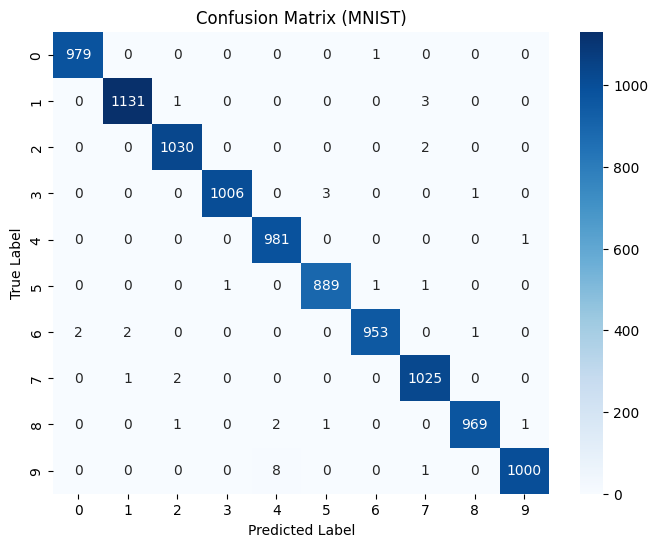

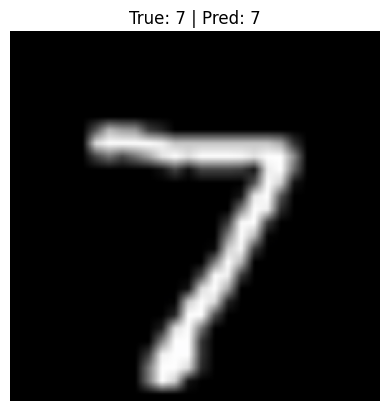

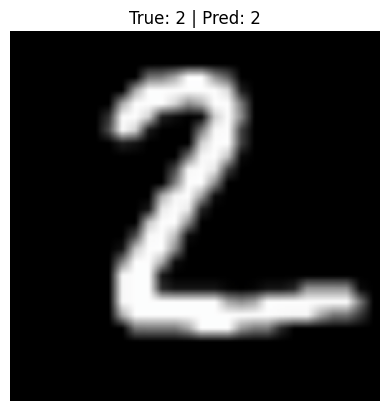

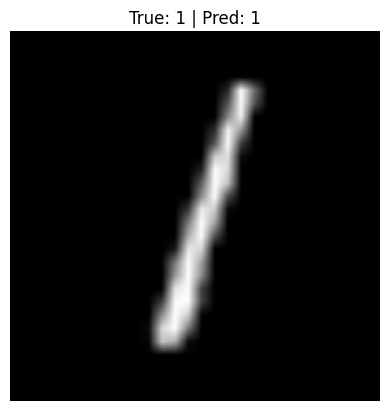

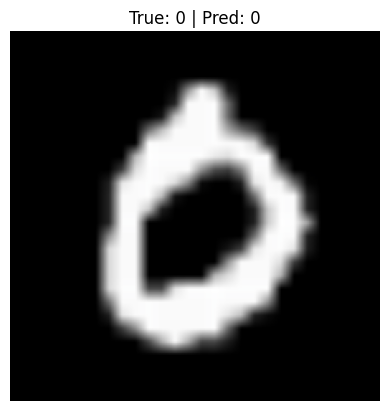

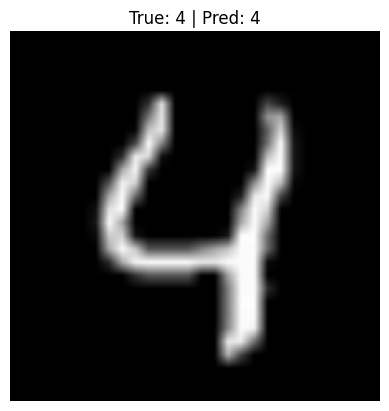

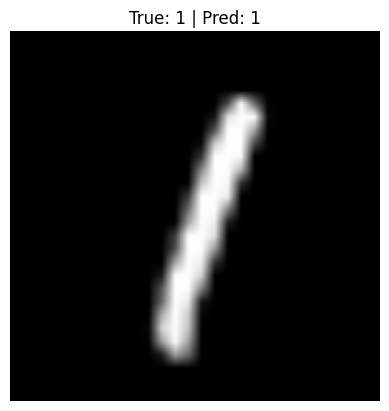

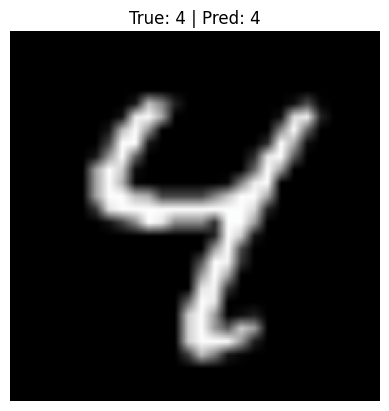

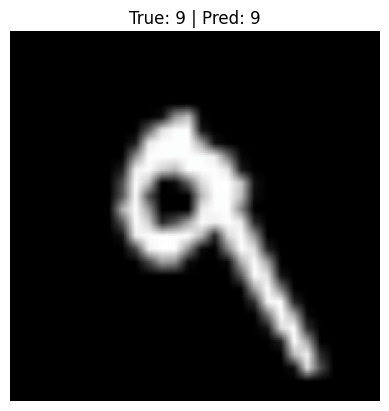

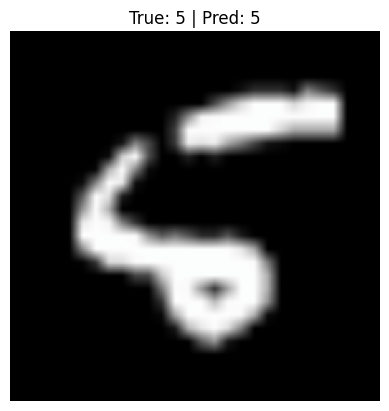

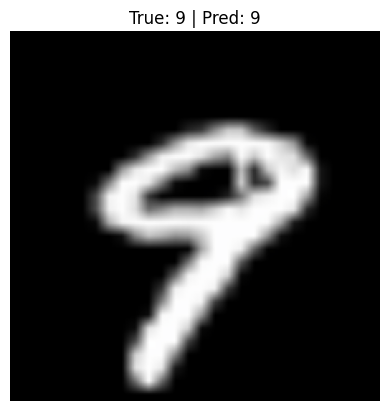

In [3]:
import torch
import torchvision
import torchvision.transforms as transforms
from torchvision.models import resnet18
import matplotlib.pyplot as plt
import numpy as np
from sklearn.metrics import confusion_matrix, classification_report, accuracy_score
import seaborn as sns

# ---------------- DEVICE ----------------
device = torch.device("cuda" if torch.cuda.is_available() else "cpu")

# ---------------- NORMALIZATION ----------------
mean = [0.485, 0.456, 0.406]
std = [0.229, 0.224, 0.225]

# ---------------- TRANSFORM (IMPORTANT SAME AS TRAIN) ----------------
transform = transforms.Compose([
    transforms.Resize(224),
    transforms.Grayscale(num_output_channels=3),
    transforms.ToTensor(),
    transforms.Normalize(mean=mean, std=std)
])

# ---------------- DATA ----------------
testset = torchvision.datasets.MNIST(
    root='./data',
    train=False,
    download=True,
    transform=transform
)

testloader = torch.utils.data.DataLoader(
    testset,
    batch_size=64,
    shuffle=False
)

# MNIST classes
classes = [str(i) for i in range(10)]

# ---------------- LOAD MODEL ----------------
model = resnet18(weights=None)

model.fc = torch.nn.Sequential(
    torch.nn.Dropout(0.5),
    torch.nn.Linear(512, 10)
)

model.load_state_dict(torch.load(
    "best_model_mnist.pth",   # your saved model
    map_location=device
))

model.to(device)
model.eval()

print("✅ Model Loaded")

# ---------------- PREDICTIONS ----------------
all_preds = []
all_labels = []

with torch.no_grad():
    for images, labels in testloader:

        images = images.to(device)
        labels = labels.to(device)

        outputs = model(images)
        _, preds = torch.max(outputs, 1)

        all_preds.extend(preds.cpu().numpy())
        all_labels.extend(labels.cpu().numpy())

# ---------------- METRICS ----------------
acc = accuracy_score(all_labels, all_preds)

print("\n✅ Accuracy:", acc)

print("\n📊 Classification Report:")
print(classification_report(all_labels, all_preds, target_names=classes))

# ---------------- CONFUSION MATRIX ----------------
cm = confusion_matrix(all_labels, all_preds)

plt.figure(figsize=(8,6))
sns.heatmap(cm, annot=True, fmt="d", cmap="Blues")
plt.title("Confusion Matrix (MNIST)")
plt.xlabel("Predicted Label")
plt.ylabel("True Label")
plt.show()

# ---------------- UNNORMALIZE FUNCTION ----------------
def unnormalize(img):
    img = img.numpy().transpose((1, 2, 0))
    img = std * img + mean
    img = np.clip(img, 0, 1)
    return img

# ---------------- SHOW SAMPLE PREDICTIONS ----------------
def show_predictions(loader, model, classes, num_images=10):

    model.eval()
    images_shown = 0

    with torch.no_grad():
        for images, labels in loader:

            images = images.to(device)
            labels = labels.to(device)

            outputs = model(images)
            _, preds = torch.max(outputs, 1)

            for i in range(images.size(0)):

                img = images[i].cpu()
                img = unnormalize(img)

                true_label = classes[labels[i].item()]
                pred_label = classes[preds[i].item()]

                plt.imshow(img)
                plt.title(f"True: {true_label} | Pred: {pred_label}")
                plt.axis("off")
                plt.show()

                images_shown += 1

                if images_shown >= num_images:
                    return

show_predictions(testloader, model, classes, 10)

# FASHION MNIST

In [1]:
import torch
import torchvision
import torchvision.transforms as transforms
from torchvision.models import resnet18
import random
import copy

# ---------------- DEVICE ----------------
device = torch.device("cuda" if torch.cuda.is_available() else "cpu")
print("Using:", device)

# ---------------- DATA TRANSFORMS ----------------
transform_train = transforms.Compose([
    transforms.Resize(224),

    # Convert grayscale → 3-channel
    transforms.Grayscale(num_output_channels=3),

    transforms.RandomRotation(10),
    transforms.ToTensor(),

    transforms.Normalize(
        mean=[0.485, 0.456, 0.406],
        std=[0.229, 0.224, 0.225]
    )
])

transform_test = transforms.Compose([
    transforms.Resize(224),
    transforms.Grayscale(num_output_channels=3),
    transforms.ToTensor(),
    transforms.Normalize(
        mean=[0.485, 0.456, 0.406],
        std=[0.229, 0.224, 0.225]
    )
])

# ---------------- DATASETS ----------------
trainset = torchvision.datasets.FashionMNIST(
    root='./data',
    train=True,
    download=True,
    transform=transform_train
)

testset = torchvision.datasets.FashionMNIST(
    root='./data',
    train=False,
    download=True,
    transform=transform_test
)

trainloader = torch.utils.data.DataLoader(
    trainset,
    batch_size=64,
    shuffle=True,
    num_workers=2
)

testloader = torch.utils.data.DataLoader(
    testset,
    batch_size=64,
    shuffle=False,
    num_workers=2
)

# ---------------- MODEL ----------------
model = resnet18(weights="IMAGENET1K_V1")

# Replace FC layer for 10 classes
model.fc = torch.nn.Sequential(
    torch.nn.Dropout(0.5),
    torch.nn.Linear(512, 10)
)

model = model.to(device)

# ---------------- FREEZE ALL ----------------
for p in model.parameters():
    p.requires_grad = False

# ---------------- ACCURACY FUNCTION ----------------
def accuracy_loader(model, loader):
    model.eval()
    correct, total = 0, 0

    with torch.no_grad():
        for x, y in loader:
            x, y = x.to(device), y.to(device)

            out = model(x)
            _, pred = out.max(1)

            total += y.size(0)
            correct += pred.eq(y).sum().item()

    return correct / total

# ---------------- INITIAL ACCURACY ----------------
best_acc = accuracy_loader(model, testloader)
print("Initial Test Accuracy:", best_acc)

# ---------------- LAYERS ----------------
layers = {
    "layer1": model.layer1,
    "layer2": model.layer2,
    "layer3": model.layer3,
    "layer4": model.layer4
}

patience = 2
no_improve_count = 0
max_iterations = 40

# ---------------- TRAINING LOOP ----------------
for i in range(max_iterations):

    print("\n========== Iteration", i + 1, "==========")

    chosen_names = random.sample(
        list(layers.keys()),
        random.choice([1, 2])
    )

    print("Unfreezing:", chosen_names)

    old_weights = copy.deepcopy(model.state_dict())

    # -------- UNFREEZE RANDOM LAYERS --------
    for name in chosen_names:
        for p in layers[name].parameters():
            p.requires_grad = True

    # -------- ALWAYS TRAIN FC --------
    for p in model.fc.parameters():
        p.requires_grad = True

    optimizer = torch.optim.AdamW(
        filter(lambda p: p.requires_grad, model.parameters()),
        lr=3e-4,
        weight_decay=1e-4
    )

    scheduler = torch.optim.lr_scheduler.CosineAnnealingLR(
        optimizer,
        T_max=5
    )

    loss_fn = torch.nn.CrossEntropyLoss(label_smoothing=0.1)

    # ---------------- TRAIN ----------------
    model.train()

    for epoch in range(5):  # Slightly reduced epochs for Fashion-MNIST

        running_loss = 0

        for x, y in trainloader:
            x, y = x.to(device), y.to(device)

            optimizer.zero_grad()
            out = model(x)
            loss = loss_fn(out, y)
            loss.backward()
            optimizer.step()

            running_loss += loss.item()

        scheduler.step()
        print(f"Epoch {epoch+1} Loss: {running_loss/len(trainloader):.4f}")

    # ---------------- EVALUATE ----------------
    train_acc = accuracy_loader(model, trainloader)
    test_acc = accuracy_loader(model, testloader)

    print("Train Accuracy:", train_acc)
    print("Test Accuracy :", test_acc)

    # ---------------- SAVE BEST MODEL ----------------
    if test_acc > best_acc:
        best_acc = test_acc
        no_improve_count = 0

        torch.save(model.state_dict(), "best_model_fashionmnist.pth")
        print("✅ Improved — Model Saved")

    else:
        model.load_state_dict(old_weights)
        no_improve_count += 1

        print("❌ Reverted | No Improve Count:", no_improve_count)

    # ---------------- FREEZE AGAIN ----------------
    for p in model.parameters():
        p.requires_grad = False

    # ---------------- EARLY STOP ----------------
    if no_improve_count >= patience:
        print("\n🛑 Early stopping triggered!")
        break

print("\nFinal Best Accuracy:", best_acc)
print("Best model saved as best_model_fashionmnist.pth")

Using: cuda


100%|██████████| 26.4M/26.4M [00:01<00:00, 16.7MB/s]
100%|██████████| 29.5k/29.5k [00:00<00:00, 265kB/s]
100%|██████████| 4.42M/4.42M [00:00<00:00, 4.95MB/s]
100%|██████████| 5.15k/5.15k [00:00<00:00, 13.0MB/s]


Downloading: "https://download.pytorch.org/models/resnet18-f37072fd.pth" to /root/.cache/torch/hub/checkpoints/resnet18-f37072fd.pth


100%|██████████| 44.7M/44.7M [00:00<00:00, 163MB/s] 


Initial Test Accuracy: 0.0844

========== Iteration 1 ==========
Unfreezing: ['layer4', 'layer2']
Epoch 1 Loss: 0.7754
Epoch 2 Loss: 0.6724
Epoch 3 Loss: 0.6316
Epoch 4 Loss: 0.5966
Epoch 5 Loss: 0.5692
Train Accuracy: 0.9870666666666666
Test Accuracy : 0.9519
✅ Improved — Model Saved

========== Iteration 2 ==========
Unfreezing: ['layer3']
Epoch 1 Loss: 0.5942
Epoch 2 Loss: 0.5788
Epoch 3 Loss: 0.5648
Epoch 4 Loss: 0.5516
Epoch 5 Loss: 0.5422
Train Accuracy: 0.9958
Test Accuracy : 0.9553
✅ Improved — Model Saved

========== Iteration 3 ==========
Unfreezing: ['layer1']
Epoch 1 Loss: 0.5489
Epoch 2 Loss: 0.5466
Epoch 3 Loss: 0.5437
Epoch 4 Loss: 0.5413
Epoch 5 Loss: 0.5392
Train Accuracy: 0.9963833333333333
Test Accuracy : 0.9551
❌ Reverted | No Improve Count: 1

========== Iteration 4 ==========
Unfreezing: ['layer2']
Epoch 1 Loss: 0.5495
Epoch 2 Loss: 0.5464
Epoch 3 Loss: 0.5424
Epoch 4 Loss: 0.5381
Epoch 5 Loss: 0.5363
Train Accuracy: 0.9974333333333333
Test Accuracy : 0.9541
❌ Rev

✅ Model Loaded

✅ Accuracy: 0.9553

📊 Classification Report:
              precision    recall  f1-score   support

     T-shirt       0.90      0.91      0.91      1000
     Trouser       1.00      1.00      1.00      1000
    Pullover       0.94      0.94      0.94      1000
       Dress       0.95      0.96      0.96      1000
        Coat       0.94      0.94      0.94      1000
      Sandal       0.99      0.99      0.99      1000
       Shirt       0.87      0.86      0.87      1000
     Sneaker       0.97      0.99      0.98      1000
         Bag       0.99      1.00      1.00      1000
  Ankle Boot       0.98      0.97      0.98      1000

    accuracy                           0.96     10000
   macro avg       0.96      0.96      0.96     10000
weighted avg       0.96      0.96      0.96     10000



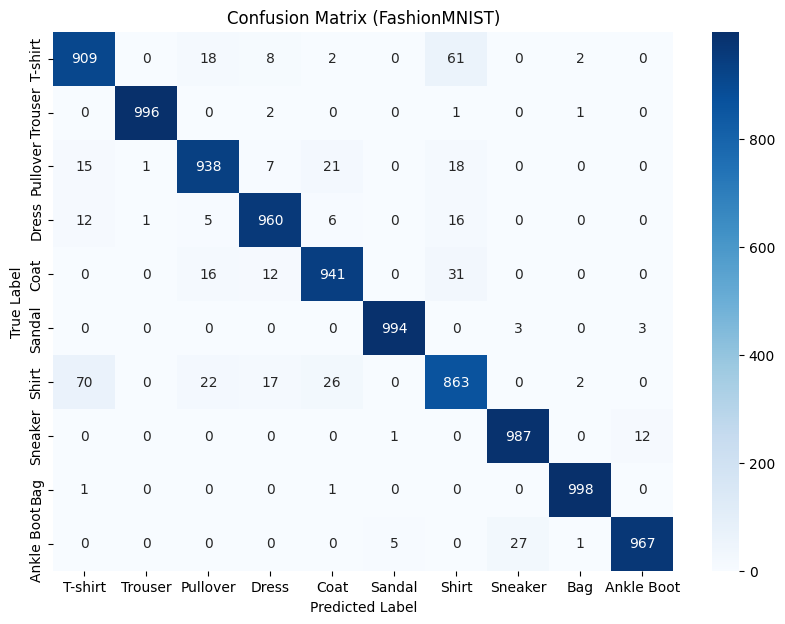

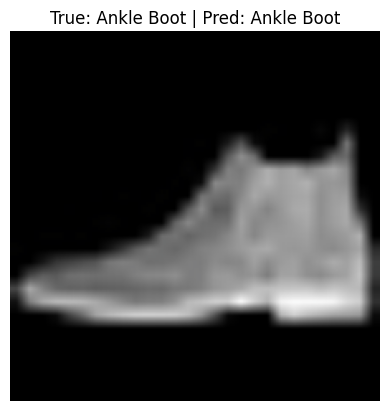

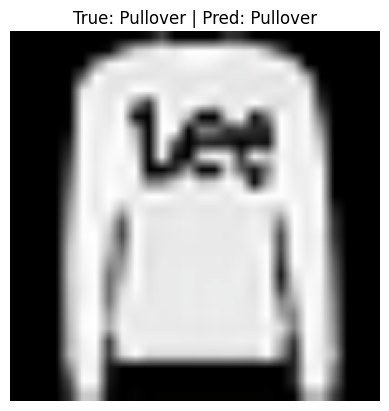

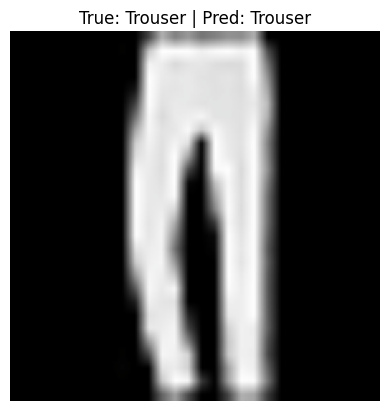

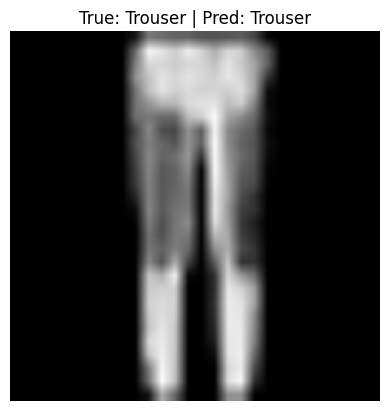

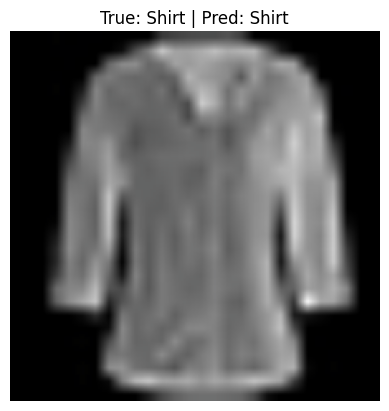

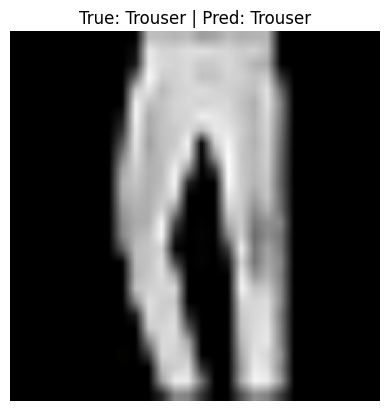

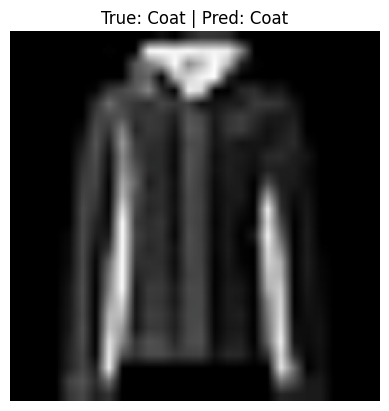

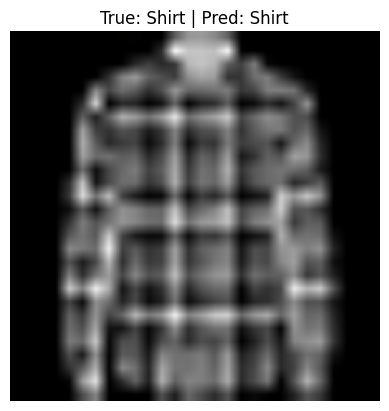

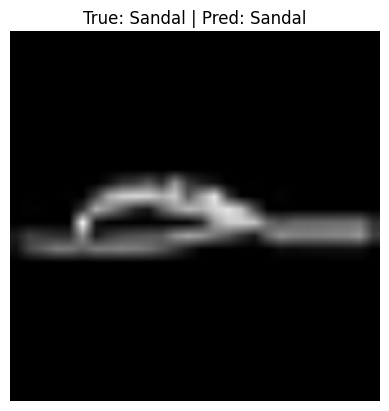

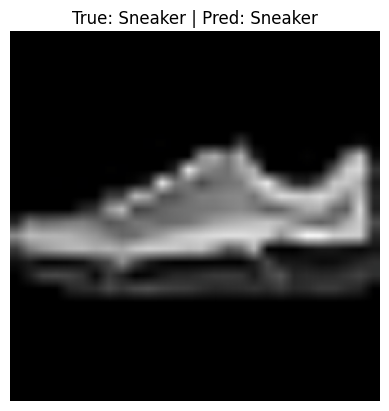

In [2]:
import torch
import torchvision
import torchvision.transforms as transforms
from torchvision.models import resnet18
import matplotlib.pyplot as plt
import numpy as np
from sklearn.metrics import confusion_matrix, classification_report, accuracy_score
import seaborn as sns

# ---------------- DEVICE ----------------
device = torch.device("cuda" if torch.cuda.is_available() else "cpu")

# ---------------- NORMALIZATION ----------------
mean = [0.485, 0.456, 0.406]
std = [0.229, 0.224, 0.225]

# ---------------- TRANSFORM (SAME AS TRAIN) ----------------
transform = transforms.Compose([
    transforms.Resize(224),
    transforms.Grayscale(num_output_channels=3),
    transforms.ToTensor(),
    transforms.Normalize(mean=mean, std=std)
])

# ---------------- DATA ----------------
testset = torchvision.datasets.FashionMNIST(
    root='./data',
    train=False,
    download=True,
    transform=transform
)

testloader = torch.utils.data.DataLoader(
    testset,
    batch_size=64,
    shuffle=False
)

# FashionMNIST classes
classes = [
    "T-shirt", "Trouser", "Pullover", "Dress", "Coat",
    "Sandal", "Shirt", "Sneaker", "Bag", "Ankle Boot"
]

# ---------------- LOAD MODEL ----------------
model = resnet18(weights=None)

model.fc = torch.nn.Sequential(
    torch.nn.Dropout(0.5),
    torch.nn.Linear(512, 10)
)

model.load_state_dict(torch.load(
    "best_model_fashionmnist.pth",   # IMPORTANT change
    map_location=device
))

model.to(device)
model.eval()

print("✅ Model Loaded")

# ---------------- PREDICTIONS ----------------
all_preds = []
all_labels = []

with torch.no_grad():
    for images, labels in testloader:

        images = images.to(device)
        labels = labels.to(device)

        outputs = model(images)
        _, preds = torch.max(outputs, 1)

        all_preds.extend(preds.cpu().numpy())
        all_labels.extend(labels.cpu().numpy())

# ---------------- METRICS ----------------
acc = accuracy_score(all_labels, all_preds)

print("\n✅ Accuracy:", acc)

print("\n📊 Classification Report:")
print(classification_report(all_labels, all_preds, target_names=classes))

# ---------------- CONFUSION MATRIX ----------------
cm = confusion_matrix(all_labels, all_preds)

plt.figure(figsize=(10,7))
sns.heatmap(cm, annot=True, fmt="d", cmap="Blues",
            xticklabels=classes, yticklabels=classes)
plt.title("Confusion Matrix (FashionMNIST)")
plt.xlabel("Predicted Label")
plt.ylabel("True Label")
plt.show()

# ---------------- UNNORMALIZE FUNCTION ----------------
def unnormalize(img):
    img = img.numpy().transpose((1, 2, 0))
    img = std * img + mean
    img = np.clip(img, 0, 1)
    return img

# ---------------- SHOW SAMPLE PREDICTIONS ----------------
def show_predictions(loader, model, classes, num_images=10):

    model.eval()
    images_shown = 0

    with torch.no_grad():
        for images, labels in loader:

            images = images.to(device)
            labels = labels.to(device)

            outputs = model(images)
            _, preds = torch.max(outputs, 1)

            for i in range(images.size(0)):

                img = images[i].cpu()
                img = unnormalize(img)

                true_label = classes[labels[i].item()]
                pred_label = classes[preds[i].item()]

                plt.imshow(img)
                plt.title(f"True: {true_label} | Pred: {pred_label}")
                plt.axis("off")
                plt.show()

                images_shown += 1

                if images_shown >= num_images:
                    return

show_predictions(testloader, model, classes, 10)

In [ ]:
import torch
import torchvision
import torchvision.transforms as transforms
from torchvision.models import vgg16
import random
import copy

# ---------------- DEVICE ----------------
device = torch.device("cuda" if torch.cuda.is_available() else "cpu")
print("Using:", device)

# ---------------- DATA TRANSFORMS ----------------
transform_train = transforms.Compose([
    transforms.Resize(224),
    transforms.Grayscale(num_output_channels=3),
    transforms.RandomRotation(10),
    transforms.ToTensor(),
    transforms.Normalize(
        mean=[0.485, 0.456, 0.406],
        std=[0.229, 0.224, 0.225]
    )
])

transform_test = transforms.Compose([
    transforms.Resize(224),
    transforms.Grayscale(num_output_channels=3),
    transforms.ToTensor(),
    transforms.Normalize(
        mean=[0.485, 0.456, 0.406],
        std=[0.229, 0.224, 0.225]
    )
])

# ---------------- DATASETS ----------------
trainset = torchvision.datasets.FashionMNIST(
    root='./data',
    train=True,
    download=True,
    transform=transform_train
)

testset = torchvision.datasets.FashionMNIST(
    root='./data',
    train=False,
    download=True,
    transform=transform_test
)

trainloader = torch.utils.data.DataLoader(
    trainset,
    batch_size=64,
    shuffle=True,
    num_workers=2
)

testloader = torch.utils.data.DataLoader(
    testset,
    batch_size=64,
    shuffle=False,
    num_workers=2
)

# ---------------- MODEL ----------------
model = vgg16(weights="IMAGENET1K_V1")

# Replace classifier last layer
model.classifier[6] = torch.nn.Sequential(
    torch.nn.Dropout(0.5),
    torch.nn.Linear(4096, 10)
)

model = model.to(device)

# ---------------- FREEZE ALL ----------------
for p in model.parameters():
    p.requires_grad = False

# ---------------- ACCURACY FUNCTION ----------------
def accuracy_loader(model, loader):
    model.eval()
    correct, total = 0, 0

    with torch.no_grad():
        for x, y in loader:
            x, y = x.to(device), y.to(device)

            out = model(x)
            _, pred = out.max(1)

            total += y.size(0)
            correct += pred.eq(y).sum().item()

    return correct / total

# ---------------- INITIAL ACCURACY ----------------
best_acc = accuracy_loader(model, testloader)
print("Initial Test Accuracy:", best_acc)

# ---------------- LAYERS (VGG STYLE) ----------------
# VGG doesn't have layer1,2,3,4 like ResNet
layers = {
    "features_1": model.features[:10],   # early conv layers
    "features_2": model.features[10:20],
    "features_3": model.features[20:30],
    "features_4": model.features[30:]
}

patience = 2
no_improve_count = 0
max_iterations = 40

# ---------------- TRAINING LOOP ----------------
for i in range(max_iterations):

    print("\n========== Iteration", i + 1, "==========")

    chosen_names = random.sample(
        list(layers.keys()),
        random.choice([1, 2])
    )

    print("Unfreezing:", chosen_names)

    old_weights = copy.deepcopy(model.state_dict())

    # -------- UNFREEZE RANDOM LAYERS --------
    for name in chosen_names:
        for p in layers[name].parameters():
            p.requires_grad = True

    # -------- ALWAYS TRAIN CLASSIFIER --------
    for p in model.classifier.parameters():
        p.requires_grad = True

    optimizer = torch.optim.AdamW(
        filter(lambda p: p.requires_grad, model.parameters()),
        lr=3e-4,
        weight_decay=1e-4
    )

    scheduler = torch.optim.lr_scheduler.CosineAnnealingLR(
        optimizer,
        T_max=5
    )

    loss_fn = torch.nn.CrossEntropyLoss(label_smoothing=0.1)

    # ---------------- TRAIN ----------------
    model.train()

    for epoch in range(5):

        running_loss = 0

        for x, y in trainloader:
            x, y = x.to(device), y.to(device)

            optimizer.zero_grad()
            out = model(x)
            loss = loss_fn(out, y)
            loss.backward()
            optimizer.step()

            running_loss += loss.item()

        scheduler.step()
        print(f"Epoch {epoch+1} Loss: {running_loss/len(trainloader):.4f}")

    # ---------------- EVALUATE ----------------
    train_acc = accuracy_loader(model, trainloader)
    test_acc = accuracy_loader(model, testloader)

    print("Train Accuracy:", train_acc)
    print("Test Accuracy :", test_acc)

    # ---------------- SAVE BEST MODEL ----------------
    if test_acc > best_acc:
        best_acc = test_acc
        no_improve_count = 0

        torch.save(model.state_dict(), "best_model_fashionmnist.pth")
        print("✅ Improved — Model Saved")

    else:
        model.load_state_dict(old_weights)
        no_improve_count += 1

        print("❌ Reverted | No Improve Count:", no_improve_count)

    # ---------------- FREEZE AGAIN ----------------
    for p in model.parameters():
        p.requires_grad = False

    # ---------------- EARLY STOP ----------------
    if no_improve_count >= patience:
        print("\n🛑 Early stopping triggered!")
        break

print("\nFinal Best Accuracy:", best_acc)
print("Best model saved as best_model_fashionmnist.pth")

Using: cuda
Downloading: "https://download.pytorch.org/models/vgg16-397923af.pth" to /root/.cache/torch/hub/checkpoints/vgg16-397923af.pth


100%|██████████| 528M/528M [00:02<00:00, 216MB/s] 


Initial Test Accuracy: 0.1143

========== Iteration 1 ==========
Unfreezing: ['features_3', 'features_1']
Epoch 1 Loss: 0.7739
Epoch 2 Loss: 0.6714
Epoch 3 Loss: 0.6269


# VGG-16 on MINI imagenet

In [1]:
import torch
import torchvision
import torchvision.transforms as transforms
from torchvision.models import vgg16
from torchvision.datasets import ImageFolder
import random
import copy

# ---------------- DEVICE ----------------
device = torch.device("cuda" if torch.cuda.is_available() else "cpu")
print("Using:", device)

# ---------------- DATA TRANSFORMS ----------------
transform_train = transforms.Compose([
    transforms.RandomResizedCrop(224),
    transforms.RandomHorizontalFlip(),
    transforms.RandomRotation(15),
    transforms.ColorJitter(0.4, 0.4, 0.4, 0.1),
    transforms.ToTensor(),
    transforms.Normalize(
        mean=[0.485, 0.456, 0.406],
        std=[0.229, 0.224, 0.225]
    )
])

transform_test = transforms.Compose([
    transforms.Resize((224, 224)),
    transforms.ToTensor(),
    transforms.Normalize(
        mean=[0.485, 0.456, 0.406],
        std=[0.229, 0.224, 0.225]
    )
])

# ---------------- DATASETS ----------------
trainset = ImageFolder(
    root="./mini_imagenet/train",
    transform=transform_train
)

testset = ImageFolder(
    root="./mini_imagenet/val",
    transform=transform_test
)

trainloader = torch.utils.data.DataLoader(
    trainset,
    batch_size=64,
    shuffle=True,
    num_workers=2
)

testloader = torch.utils.data.DataLoader(
    testset,
    batch_size=64,
    shuffle=False,
    num_workers=2
)

print("Classes:", len(trainset.classes))

# ---------------- MODEL ----------------
model = vgg16(weights="IMAGENET1K_V1")

# Replace classifier for 100 classes
model.classifier[6] = torch.nn.Sequential(
    torch.nn.Dropout(0.5),
    torch.nn.Linear(4096, 100)
)

model = model.to(device)

# ---------------- FREEZE ALL ----------------
for p in model.parameters():
    p.requires_grad = False

# ---------------- ACCURACY FUNCTION ----------------
def accuracy_loader(model, loader):
    model.eval()
    correct, total = 0, 0

    with torch.no_grad():
        for x, y in loader:
            x, y = x.to(device), y.to(device)

            out = model(x)
            _, pred = out.max(1)

            total += y.size(0)
            correct += pred.eq(y).sum().item()

    return correct / total

# ---------------- INITIAL ACCURACY ----------------
best_acc = accuracy_loader(model, testloader)
print("Initial Test Accuracy:", best_acc)

# ---------------- LAYER GROUPS ----------------
layers = {
    "features_1": model.features[:10],
    "features_2": model.features[10:20],
    "features_3": model.features[20:30],
    "features_4": model.features[30:]
}

patience = 3
no_improve_count = 0
max_iterations = 40

# ---------------- TRAINING LOOP ----------------
for i in range(max_iterations):

    print("\n========== Iteration", i + 1, "==========")

    chosen_names = random.sample(
        list(layers.keys()),
        random.choice([1, 2])
    )

    print("Unfreezing:", chosen_names)

    old_weights = copy.deepcopy(model.state_dict())

    # -------- UNFREEZE RANDOM LAYERS --------
    for name in chosen_names:
        for p in layers[name].parameters():
            p.requires_grad = True

    # -------- ALWAYS TRAIN CLASSIFIER --------
    for p in model.classifier.parameters():
        p.requires_grad = True

    optimizer = torch.optim.AdamW(
        filter(lambda p: p.requires_grad, model.parameters()),
        lr=3e-4,
        weight_decay=1e-4
    )

    scheduler = torch.optim.lr_scheduler.CosineAnnealingLR(
        optimizer,
        T_max=5
    )

    loss_fn = torch.nn.CrossEntropyLoss(label_smoothing=0.1)

    # ---------------- TRAIN ----------------
    model.train()

    for epoch in range(5):

        running_loss = 0

        for x, y in trainloader:
            x, y = x.to(device), y.to(device)

            optimizer.zero_grad()
            out = model(x)
            loss = loss_fn(out, y)
            loss.backward()
            optimizer.step()

            running_loss += loss.item()

        scheduler.step()
        print(f"Epoch {epoch+1} Loss: {running_loss/len(trainloader):.4f}")

    # ---------------- EVALUATE ----------------
    train_acc = accuracy_loader(model, trainloader)
    test_acc = accuracy_loader(model, testloader)

    print("Train Accuracy:", train_acc)
    print("Test Accuracy :", test_acc)

    # ---------------- SAVE BEST MODEL ----------------
    if test_acc > best_acc:
        best_acc = test_acc
        no_improve_count = 0

        torch.save(model.state_dict(), "best_model_miniimagenet.pth")
        print("✅ Improved — Model Saved")

    else:
        model.load_state_dict(old_weights)
        no_improve_count += 1
        print("❌ Reverted | No Improve Count:", no_improve_count)

    # ---------------- FREEZE AGAIN ----------------
    for p in model.parameters():
        p.requires_grad = False

    # ---------------- EARLY STOP ----------------
    if no_improve_count >= patience:
        print("\n🛑 Early stopping triggered!")
        break

print("\nFinal Best Accuracy:", best_acc)
print("Best model saved as best_model_miniimagenet.pth")

Using: cuda


FileNotFoundError: [Errno 2] No such file or directory: './mini_imagenet/train'

In [ ]:
import torch
import torch.nn as nn
import torchvision
import torchvision.transforms as transforms
from torchvision.models import resnet18

# ---------------- DEVICE ----------------
device = torch.device("cuda" if torch.cuda.is_available() else "cpu")
print("Using:", device)

# ---------------- TRANSFORMS ----------------
transform = transforms.Compose([
    transforms.Resize(224),
    transforms.ToTensor()
])

# ---------------- DATA ----------------
trainset = torchvision.datasets.CIFAR100(
    root='./data', train=True, download=True, transform=transform)

testset = torchvision.datasets.CIFAR100(
    root='./data', train=False, download=True, transform=transform)

trainloader = torch.utils.data.DataLoader(trainset, batch_size=64, shuffle=True)
testloader = torch.utils.data.DataLoader(testset, batch_size=64, shuffle=False)

# ---------------- MODEL ----------------
model = resnet18(pretrained=True)

# Freeze ALL layers
for param in model.parameters():
    param.requires_grad = False

# Replace final FC layer
model.fc = nn.Linear(model.fc.in_features, 100)

# Only FC layer should train
for param in model.fc.parameters():
    param.requires_grad = True

model = model.to(device)

# ---------------- LOSS + OPTIMIZER ----------------
criterion = nn.CrossEntropyLoss()

optimizer = torch.optim.AdamW(
    model.fc.parameters(),
    lr=3e-4
)

# ---------------- ACCURACY FUNCTION ----------------
def accuracy(loader):
    model.eval()
    correct = 0
    total = 0

    with torch.no_grad():
        for x, y in loader:
            x, y = x.to(device), y.to(device)
            outputs = model(x)
            _, predicted = torch.max(outputs, 1)

            total += y.size(0)
            correct += (predicted == y).sum().item()

    return 100 * correct / total

# ---------------- TRAINING ----------------
epochs = 5

for epoch in range(epochs):
    model.train()
    running_loss = 0

    for x, y in trainloader:
        x, y = x.to(device), y.to(device)

        optimizer.zero_grad()

        outputs = model(x)
        loss = criterion(outputs, y)

        loss.backward()
        optimizer.step()

        running_loss += loss.item()

    train_acc = accuracy(trainloader)
    test_acc = accuracy(testloader)

    print(f"\nEpoch {epoch+1}")
    print(f"Loss: {running_loss/len(trainloader):.4f}")
    print(f"Train Accuracy: {train_acc:.2f}%")
    print(f"Test Accuracy : {test_acc:.2f}%")

print("\n✅ Training Completed")

Using: cuda


100%|██████████| 169M/169M [00:04<00:00, 38.2MB/s] 
/usr/local/lib/python3.12/dist-packages/torchvision/models/_utils.py:208: UserWarning: The parameter 'pretrained' is deprecated since 0.13 and may be removed in the future, please use 'weights' instead.
  warnings.warn(
/usr/local/lib/python3.12/dist-packages/torchvision/models/_utils.py:223: UserWarning: Arguments other than a weight enum or `None` for 'weights' are deprecated since 0.13 and may be removed in the future. The current behavior is equivalent to passing `weights=ResNet18_Weights.IMAGENET1K_V1`. You can also use `weights=ResNet18_Weights.DEFAULT` to get the most up-to-date weights.
  warnings.warn(msg)


Downloading: "https://download.pytorch.org/models/resnet18-f37072fd.pth" to /root/.cache/torch/hub/checkpoints/resnet18-f37072fd.pth


100%|██████████| 44.7M/44.7M [00:00<00:00, 142MB/s] 



Epoch 1
Loss: 3.1550
Train Accuracy: 50.68%
Test Accuracy : 48.93%
